# Reto 2 — Predicción de accidentalidad vial en El Poblado

**Aprendizaje Automático 2026-2 · Profesor: Pablo Andrés Saldarriaga · Universidad EAFIT**

**Realizado por: Santiago Vélez Casallas**

**Objetivo:** estimar, para cada pareja (barrio, hora) de los 22 barrios de El Poblado, la probabilidad de que ocurra
**al menos un accidente de tránsito**, para que la Secretaría de Movilidad decida dónde y a qué hora ubicar a sus agentes.

**Métrica:** ROC-AUC sobre el periodo de evaluación (2019-08-01 a 2019-12-30, 80.256 parejas con etiqueta oculta).

| Referencia (README) | ROC-AUC |
|---|---|
| Aleatorio | 0.5000 |
| Tasa histórica barrio × hora | 0.7589 |
| Baseline del profesor | 0.7739 |

> ### RESULTADO OFICIAL (leaderboard): ROC-AUC = **0.7838**
> Modelo: **LightGBM global** con barrio + calendario + tendencia. Validación walk-forward en 6 cortes: **0.7845**
> en promedio (sección 8).

**Ruta del notebook (sigue el README punto por punto):** 1. Exploración y calidad · 2. Target y unión de tablas ·
3. Variables · 4. Validación · 5. Modelado · 6. Desbalance y umbral · 7. Métricas más allá del ROC-AUC ·
8. Resultado oficial · 9. Caso de uso y limitaciones.

**Entorno.** El entorno del curso (`uv sync` con el `pyproject.toml` del repositorio) trae numpy, pandas,
scikit-learn y matplotlib. Este notebook usa además `lightgbm`, `seaborn` e `imbalanced-learn` (SMOTE). La celda
siguiente instala solo las que falten y funciona en Google Colab, en el entorno `uv` y en una instalación normal de
Python. La base de datos (~85 MB) se descarga sola si no está en la carpeta. El notebook completo tarda unos 5 minutos.

In [1]:
import importlib.util, subprocess, sys, shutil

REQUERIDAS = {"lightgbm": "lightgbm", "seaborn": "seaborn", "imblearn": "imbalanced-learn"}
faltan = [pkg for mod, pkg in REQUERIDAS.items() if importlib.util.find_spec(mod) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    if importlib.util.find_spec("pip") is not None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
    elif shutil.which("uv"):
        subprocess.check_call(["uv", "pip", "install", "--python", sys.executable, *faltan])
    else:
        raise RuntimeError(f"Instale manualmente: {' '.join(faltan)}")
    importlib.invalidate_caches()
print("Dependencias listas.")

Dependencias listas.


In [2]:
import os, sqlite3, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import lightgbm as lgb
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC

warnings.filterwarnings("ignore")
SEED = 0
AZUL, NARANJA, VERDE, AMARILLO, VIOLETA, ROJO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948", "#8a8984"
sns.set_theme(style="whitegrid", context="notebook", palette=[AZUL, NARANJA, VERDE, AMARILLO, VIOLETA, ROJO])
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 120)

def tabla(df, n, titulo):
    print(f"Tabla {n} — {titulo}")
    display(df)

In [3]:
URL = ("https://d3qixogk4zgixq.cloudfront.net/data/prediccion-accidentalidad-poblado/"
       "data_accidentes_poblado.sqlite3")
DB = "data_accidentes_poblado.sqlite3"
if not os.path.exists(DB):
    urllib.request.urlretrieve(URL, DB)
con = sqlite3.connect(DB)
clima = pd.read_sql("SELECT * FROM clima", con)
acc = pd.read_sql("SELECT * FROM accidentes", con)
raw = pd.read_sql("SELECT * FROM raw_accidentes", con)
print(f"clima {clima.shape} | accidentes {acc.shape} | raw_accidentes {raw.shape}")

clima (577720, 15) | accidentes (9138, 4) | raw_accidentes (9428, 16)


## 1. Exploración y calidad de datos

### 1.1 Estructura general

In [4]:
resumen = pd.DataFrame({
    "filas": [len(clima), len(acc), len(raw)],
    "columnas": [clima.shape[1], acc.shape[1], raw.shape[1]],
    "TW mínimo": [clima.TW.min(), acc.TW.min(), raw.TW.min()],
    "TW máximo": [clima.TW.max(), acc.TW.max(), raw.TW.max()],
    "barrios": [clima.BARRIO.nunique(), acc.BARRIO.nunique(), raw.BARRIO.nunique()],
    "celdas faltantes": [int(clima.isna().sum().sum()), int(acc.isna().sum().sum()), int(raw.isna().sum().sum())],
}, index=["clima", "accidentes", "raw_accidentes"])
tabla(resumen, 1, "Las tres tablas del SQLite")
print("Mismos 22 barrios, escritos igual, en las tres tablas:", set(clima.BARRIO) == set(acc.BARRIO) == set(raw.BARRIO))
print("Pares (barrio, hora) duplicados — clima:", int(clima.duplicated(["BARRIO", "TW"]).sum()),
      "| accidentes:", int(acc.duplicated(["BARRIO", "TW"]).sum()))

Tabla 1 — Las tres tablas del SQLite


,filas,columnas,TW mínimo,TW máximo,barrios,celdas faltantes
clima,577720,15,2017-01-01 00:00:00,2019-12-31 23:00:00,22,235132
accidentes,9138,4,2017-01-01 14:00:00,2019-07-31 18:00:00,22,0
raw_accidentes,9428,16,2017-01-01 14:00:00,2019-07-31 18:00:00,22,21


Mismos 22 barrios, escritos igual, en las tres tablas: True


Pares (barrio, hora) duplicados — clima: 0 | accidentes: 0


En la Tabla 1:

1. `clima` es el **universo**: una fila por barrio y hora de 2017 a 2019 (577.720 filas). `accidentes` y
   `raw_accidentes` llegan solo hasta el **2019-07-31**: después de esa fecha están las etiquetas ocultas.
2. `accidentes` tiene 9.138 parejas (barrio, hora) positivas y `raw_accidentes` 9.428 accidentes individuales. La
   diferencia son horas con más de un accidente en el mismo barrio (sección 2).
3. Los 22 barrios están escritos igual en las tres tablas y no hay parejas duplicadas.
4. `clima` tiene 235.132 celdas faltantes; `raw_accidentes`, 21. Se revisan en 1.4 y 1.5.

### 1.2 Distribución temporal

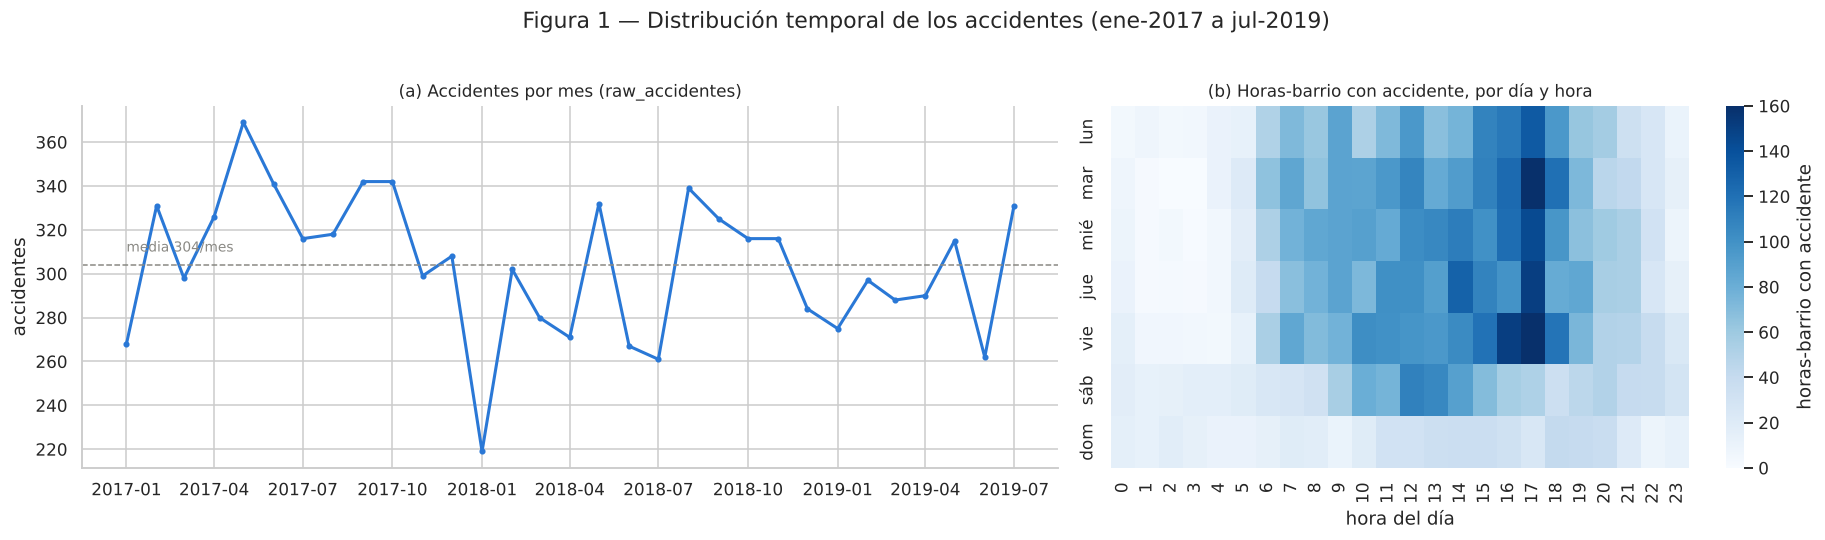

Accidentes por año: {2017: 3858, 2018: 3512, 2019: 2058} (2019 solo hasta julio)
Mes mínimo: 2018-01 219 | mes máximo: 2017-05 369


In [5]:
for d in (clima, acc, raw):
    d["TW"] = pd.to_datetime(d.TW)
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

fig, ax = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1.35, 1]))
m = raw.groupby(raw.TW.dt.to_period("M")).size()
m.index = m.index.to_timestamp()
ax[0].plot(m.index, m.values, color=AZUL, lw=2, marker="o", ms=3)
ax[0].axhline(m.mean(), color=GRIS, ls="--", lw=1)
ax[0].text(m.index[0], m.mean() + 6, f"media {m.mean():.0f}/mes", color=GRIS, fontsize=9)
ax[0].set(title="(a) Accidentes por mes (raw_accidentes)", ylabel="accidentes", xlabel="")
hm = acc.groupby([acc.TW.dt.dayofweek, acc.TW.dt.hour]).size().unstack(fill_value=0)
hm.index = DIAS
sns.heatmap(hm, cmap="Blues", ax=ax[1], cbar_kws=dict(label="horas-barrio con accidente"))
ax[1].set(title="(b) Horas-barrio con accidente, por día y hora", xlabel="hora del día", ylabel="")
fig.suptitle("Figura 1 — Distribución temporal de los accidentes (ene-2017 a jul-2019)", y=1.02)
plt.tight_layout(); plt.show()
por_ano = raw.groupby(raw.TW.dt.year).size()
print("Accidentes por año:", por_ano.to_dict(), "(2019 solo hasta julio)")
print("Mes mínimo:", m.idxmin().strftime("%Y-%m"), int(m.min()), "| mes máximo:", m.idxmax().strftime("%Y-%m"), int(m.max()))

**Lectura de la Figura 1:**

1. **(a) Nivel mensual:** unos 304 accidentes por mes, entre 219 (ene-2018) y 369 (may-2017). No hay una tendencia
   fuerte: 3.858 en 2017 y 3.512 en 2018. Los meses bajos coinciden con vacaciones (enero, mitad de año).
2. **(b) Perfil semanal:** el patrón dominante es la **hora del día**. De lunes a viernes el riesgo sube desde las 6 h
   y tiene su máximo a las **17 h**. El sábado el pico se adelanta al mediodía, y el domingo es bajo y plano.
   Barrio, hora y tipo de día son la base de todo el modelo.

### 1.3 Distribución espacial

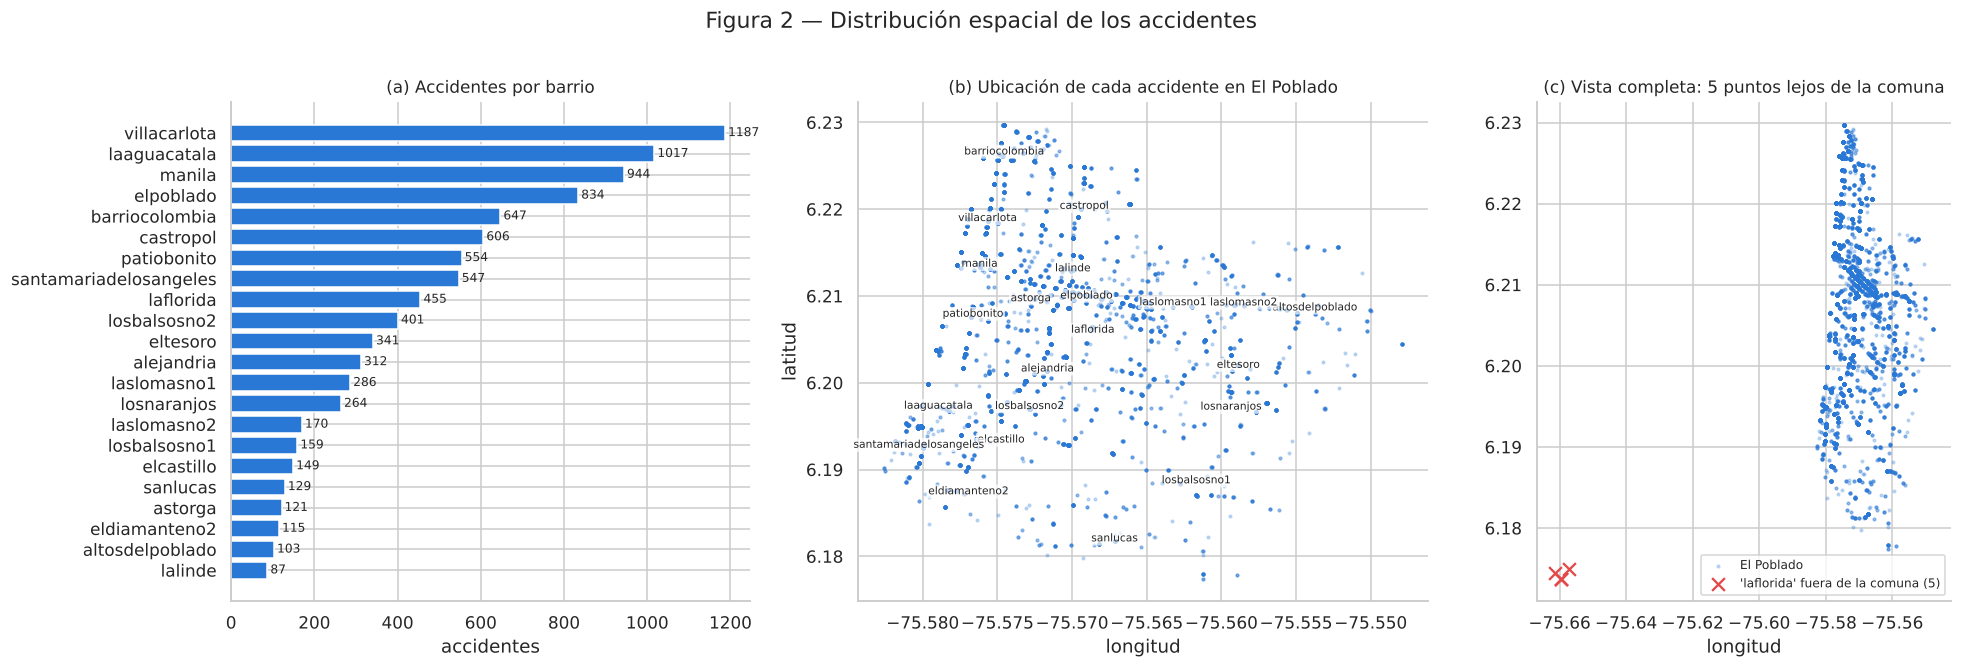

Barrio con más accidentes: villacarlota (1187); con menos: lalinde (87). Razón máx/mín = 14x


In [6]:
fuera = raw.Lon < -75.62
fig, ax = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw=dict(width_ratios=[1, 1.1, 0.8]))
cnt = raw.BARRIO.value_counts().sort_values()
ax[0].barh(cnt.index, cnt.values, color=AZUL)
ax[0].bar_label(ax[0].containers[0], padding=2, fontsize=8)
ax[0].set(title="(a) Accidentes por barrio", xlabel="accidentes")
ax[1].scatter(raw.Lon[~fuera], raw.Lat[~fuera], s=3, alpha=.25, color=AZUL)
cent = raw[~fuera].groupby("BARRIO")[["Lon", "Lat"]].median()
for b, r in cent.iterrows():
    ax[1].annotate(b, (r.Lon, r.Lat), fontsize=7, ha="center", color="#222",
                   bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.7))
ax[1].set(title="(b) Ubicación de cada accidente en El Poblado", xlabel="longitud", ylabel="latitud")
ax[2].scatter(raw.Lon[~fuera], raw.Lat[~fuera], s=3, alpha=.25, color=AZUL, label="El Poblado")
ax[2].scatter(raw.Lon[fuera], raw.Lat[fuera], s=70, color=ROJO, marker="x", label=f"'laflorida' fuera de la comuna ({fuera.sum()})")
ax[2].set(title="(c) Vista completa: 5 puntos lejos de la comuna", xlabel="longitud")
ax[2].legend(fontsize=8, loc="lower right")
fig.suptitle("Figura 2 — Distribución espacial de los accidentes", y=1.01)
plt.tight_layout(); plt.show()
print(f"Barrio con más accidentes: {cnt.index[-1]} ({cnt.iloc[-1]}); con menos: {cnt.index[0]} ({cnt.iloc[0]}). "
      f"Razón máx/mín = {cnt.iloc[-1] / cnt.iloc[0]:.0f}x")

**Lectura de la Figura 2:**

1. **(a)** El riesgo es muy desigual entre barrios: Villa Carlota tiene 1.187 accidentes y Lalinde 87 (**14 veces**
   menos). Cuatro barrios (Villa Carlota, La Aguacatala, Manila y El Poblado) concentran el 42 % de los accidentes.
2. **(b)** Los accidentes se agrupan sobre las vías principales. El barrio, como variable categórica, resume bien esta
   geografía.
3. **(c)** Hay **5 accidentes de `laflorida`** geocodificados en longitud −75.66, a unos 10 km, en el corregimiento de
   San Antonio de Prado. Es un error de geocodificación (1.5).

### 1.4 Clima

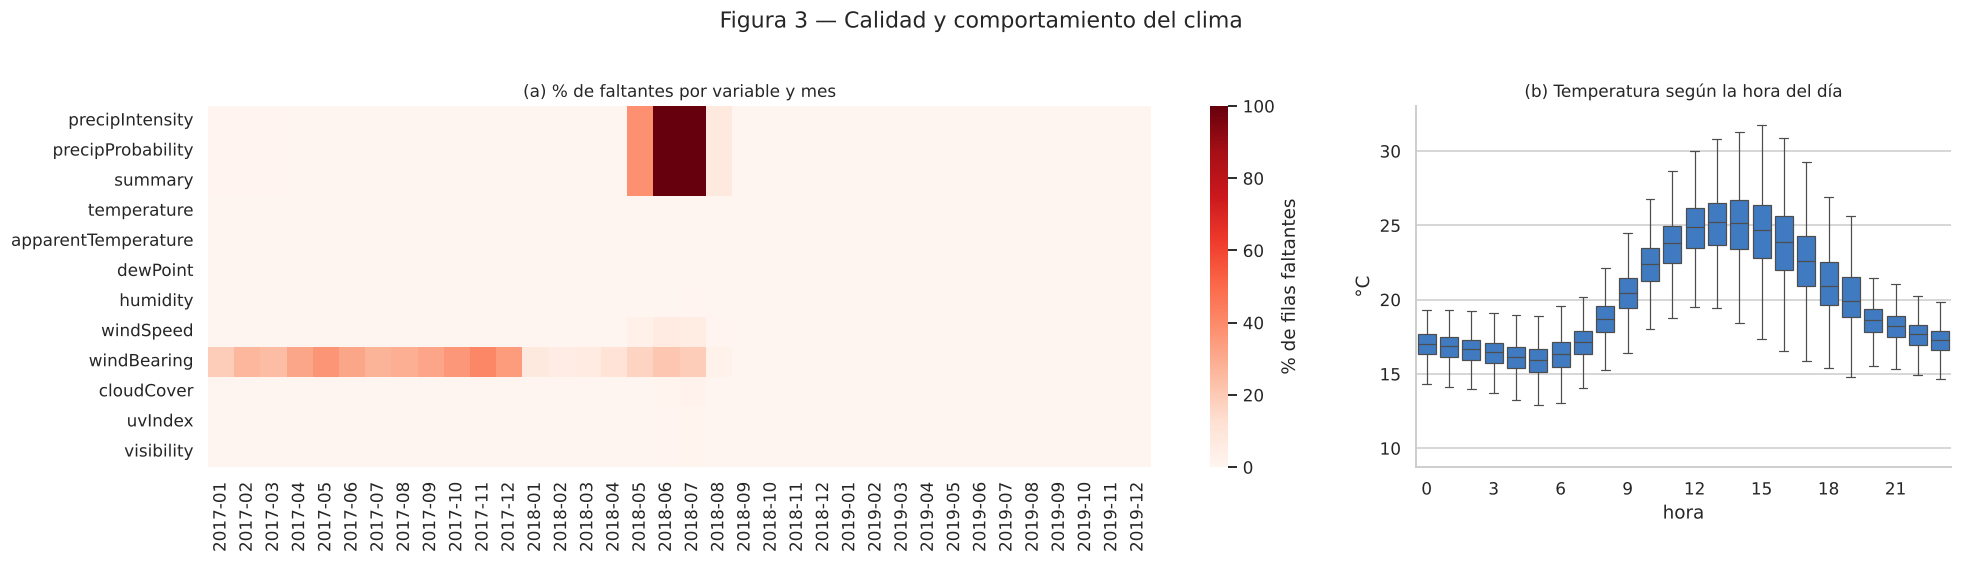

Tabla 2 — Faltantes por variable de clima


,faltantes,% del total
windBearing,73376,12.70
summary,39551,6.85
precipProbability,39463,6.83
precipIntensity,39463,6.83
windSpeed,2364,0.41
cloudCover,572,0.10
visibility,308,0.05
uvIndex,308,0.05
humidity,66,0.01
temperature,44,0.01


precipIntensity faltante: 1801 horas distintas, entre 2017-01-12 y 2018-08-03; en esas horas falta en 100% de los barrios
windBearing faltante con windSpeed = 0 (viento en calma): 57,746 de 73,376


Correlación de la temperatura entre barrios a la misma hora: 0.997


In [7]:
VARS_CLIMA = ["precipIntensity", "precipProbability", "summary", "temperature", "apparentTemperature", "dewPoint",
              "humidity", "windSpeed", "windBearing", "cloudCover", "uvIndex", "visibility"]
falt = (clima.groupby(clima.TW.dt.to_period("M"))[VARS_CLIMA].apply(lambda g: g.isna().mean() * 100)).T
falt.columns = [c.strftime("%Y-%m") for c in falt.columns]
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw=dict(width_ratios=[2.2, 1]))
sns.heatmap(falt, cmap="Reds", vmin=0, vmax=100, ax=ax[0], cbar_kws=dict(label="% de filas faltantes"))
ax[0].set(title="(a) % de faltantes por variable y mes", xlabel="", ylabel="")
sns.boxplot(x=clima.TW.dt.hour, y=clima.temperature, color=AZUL, fliersize=0, linewidth=.8, ax=ax[1])
ax[1].set(title="(b) Temperatura según la hora del día", xlabel="hora", ylabel="°C")
ax[1].set_xticks(range(0, 24, 3))
fig.suptitle("Figura 3 — Calidad y comportamiento del clima", y=1.02)
plt.tight_layout(); plt.show()

nan = clima[VARS_CLIMA].isna().sum()
calma = (clima.windBearing.isna() & (clima.windSpeed == 0)).sum()
t2 = pd.DataFrame({"faltantes": nan, "% del total": (100 * nan / len(clima)).round(2)}).sort_values("faltantes", ascending=False)
tabla(t2, 2, "Faltantes por variable de clima")
bloque = clima[clima.precipIntensity.isna()].TW
print(f"precipIntensity faltante: {bloque.dt.floor('h').nunique()} horas distintas, "
      f"entre {bloque.min():%Y-%m-%d} y {bloque.max():%Y-%m-%d}; "
      f"en esas horas falta en {clima[clima.TW.isin(bloque)].groupby('TW').precipIntensity.apply(lambda s: s.isna().mean()).mean():.0%} de los barrios")
print(f"windBearing faltante con windSpeed = 0 (viento en calma): {calma:,} de {int(nan['windBearing']):,}")
print("Correlación de la temperatura entre barrios a la misma hora:",
      round(clima.pivot_table(index="TW", columns="BARRIO", values="temperature").corr().values[np.triu_indices(22, 1)].mean(), 3))

**Lectura de la Figura 3 y la Tabla 2:**

1. **Bloque sin lluvia:** `precipIntensity`, `precipProbability` y `summary` faltan en 39.463 filas (6.8 %). Son
   1.801 horas, casi todas entre mayo y agosto de 2018 (Figura 3a), y en cada una falta para los **22 barrios a la
   vez**: es una caída de la fuente, no un hueco por barrio.
2. **`windBearing`** falta en el 12.7 % de las filas, y 57.746 de esas 73.376 tienen `windSpeed = 0`: sin viento no hay
   dirección. No es un error.
3. **El resto de variables** tiene menos del 0.5 % de faltantes.
4. **El clima es prácticamente el mismo en los 22 barrios** (correlación de la temperatura entre barrios a la misma
   hora: 0.997). La Figura 3b muestra que la temperatura sigue un ciclo diario de ~16 °C de madrugada a ~25 °C a
   mediodía, el mismo ciclo que el tráfico.

### 1.5 Inconsistencias entre tablas

In [8]:
h = raw.HORA.astype(str)
fmt_ampm = h.str.match(r"^\d{1,2}:\d{2} (AM|PM)$")
fmt_largo = h.str.match(r"^\d{1,2}:\d{2}:\d{2} (a|p)\. m\.$")

def hora_24(s):
    hh, pm = int(s.split(":")[0]), ("PM" in s) or ("p. m." in s)
    return hh % 12 + (12 if pm else 0)

h24 = h.map(hora_24)
no_coincide = h24 != raw.TW.dt.hour
HORAS = pd.date_range("2017-01-01", "2019-12-31 23:00", freq="h")
horas_sin_clima = HORAS.difference(clima.TW.unique())
pares_acc = set(zip(acc.BARRIO, acc.TW))
pares_raw = set(zip(raw.BARRIO, raw.TW))

inv = pd.DataFrame([
    ["raw: HORA en formato «hh:mm AM/PM»", fmt_ampm.sum(), f"hasta {raw.TW[fmt_ampm].max():%Y-%m-%d}"],
    ["raw: HORA en formato «hh:mm:ss a. m./p. m.»", fmt_largo.sum(), f"desde {raw.TW[fmt_largo].min():%Y-%m-%d}"],
    ["raw: HORA no coincide con la hora de TW", no_coincide.sum(), "error AM/PM (Tabla 4)"],
    ["raw: 'laflorida' geocodificado en San Antonio de Prado", fuera.sum(), "COMUNA = Corregimiento de San Antonio de Prado"],
    ["raw: COMUNA con el nombre de un barrio", (~raw.COMUNA.isin(["El Poblado", "Corregimiento de San Antonio de Prado"])).sum(), "coordenadas dentro de El Poblado"],
    ["raw: CLASE «Caída Ocupante» vs «Caida Ocupante»", (raw.CLASE == "Caída Ocupante").sum(), "misma categoría escrita distinto"],
    ["raw: RADICADO con sufijo «.0»", raw.RADICADO.astype(str).str.endswith(".0").sum(), "mezcla entero y texto"],
    ["raw: DISENO faltante", raw.DISENO.isna().sum(), ""],
    ["accidentes vs raw: pares (barrio, hora) distintos", len(pares_acc ^ pares_raw), f"{len(pares_acc):,} pares en ambas"],
    ["clima: horas sin fila (para los 22 barrios)", len(horas_sin_clima), f"{22 * len(horas_sin_clima)} filas; {acc.TW.isin(horas_sin_clima).sum()} con accidente"],
    ["clima: precipIntensity faltante", clima.precipIntensity.isna().sum(), "casi todo entre may y ago de 2018 (Figura 3a)"],
    ["clima: windBearing faltante", clima.windBearing.isna().sum(), f"{calma:,} con viento en calma"],
], columns=["problema", "filas", "detalle"])
tabla(inv, 3, "Inventario de inconsistencias")
tabla(raw.loc[no_coincide, ["RADICADO", "FECHA", "HORA", "TW", "BARRIO", "CLASE"]], 4, "Registros cuya HORA no coincide con TW")

Tabla 3 — Inventario de inconsistencias


,problema,filas,detalle
0,raw: HORA en formato «hh:mm AM/PM»,5259,hasta 2018-05-31
1,raw: HORA en formato «hh:mm:ss a. m./p. m.»,4169,desde 2018-02-06
2,raw: HORA no coincide con la hora de TW,1,error AM/PM (Tabla 4)
3,raw: 'laflorida' geocodificado en San Antonio de Prado,5,COMUNA = Corregimiento de San Antonio de Prado
4,raw: COMUNA con el nombre de un barrio,4,coordenadas dentro de El Poblado
5,raw: CLASE «Caída Ocupante» vs «Caida Ocupante»,1,misma categoría escrita distinto
6,raw: RADICADO con sufijo «.0»,3512,mezcla entero y texto
7,raw: DISENO faltante,21,
8,"accidentes vs raw: pares (barrio, hora) distintos",0,"9,138 pares en ambas"
9,clima: horas sin fila (para los 22 barrios),20,440 filas; 5 con accidente


Tabla 4 — Registros cuya HORA no coincide con TW


,RADICADO,FECHA,HORA,TW,BARRIO,CLASE
9213,1679135,2019-07-20,01:12:00 p. m.,2019-07-20 01:00:00,manila,Choque


**Lectura de las Tablas 3 y 4 (qué se encontró y qué se decidió):**

1. **`HORA` en dos formatos:** «11:10 AM» hasta may-2018 y «03:20:00 p. m.» desde feb-2018. Unificados a 24 h, coinciden
   con la hora de `TW` en **todos los registros menos uno** (Tabla 4): el radicado 1679135 dice 01:12 p. m. y quedó
   registrado a la 01:00. Es un error AM/PM.
2. **5 accidentes de `laflorida` en San Antonio de Prado** (Figura 2c). Otros 4 traen el nombre del barrio en `COMUNA`
   pero sus coordenadas están dentro de El Poblado: esos son correctos.
3. **`CLASE`** tiene «Caída Ocupante» (1) y «Caida Ocupante» (376); **`RADICADO`** mezcla «123» y «123.0»; **`DISENO`**
   tiene 21 vacíos. Son problemas de formato que no afectan el target.
4. **`accidentes` y `raw_accidentes` coinciden al 100 %**: los 9.138 pares (barrio, hora) son los mismos en ambas.
5. **Faltan 20 horas completas en `clima`** (440 filas), y en ellas hubo 5 accidentes.

El efecto de corregir 1 y 2 sobre el target se mide en 2.1.

### 1.6 ¿Hace falta imputar el clima?

Antes de imputar hay que saber si el clima aporta. Para cada variable medimos el ROC-AUC que logra sola, de dos
formas: **en bruto** y **dentro de la misma pareja barrio × hora**. Para la segunda se usa la posición del valor
frente a los demás valores de ese barrio a esa misma hora, así que la pregunta es: *a las 17 h en Manila, ¿hay más
accidentes cuando hace más calor?*

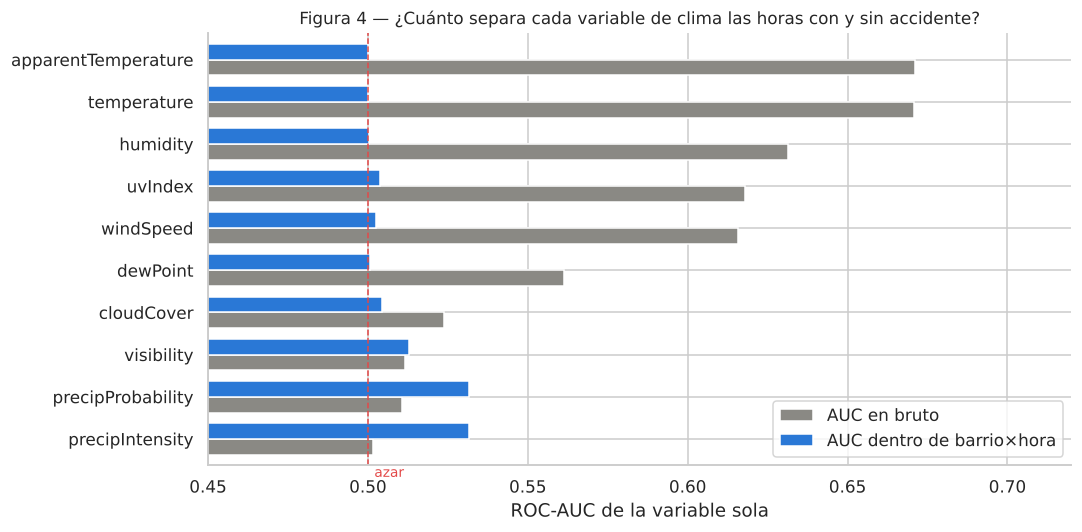

Tabla 5 — ROC-AUC de cada variable de clima, en bruto y dentro de la misma pareja barrio × hora


,AUC en bruto,AUC dentro de barrio×hora
variable,,
precipIntensity,0.502,0.532
precipProbability,0.511,0.531
visibility,0.512,0.513
cloudCover,0.524,0.504
dewPoint,0.561,0.501
windSpeed,0.616,0.502
uvIndex,0.618,0.504
humidity,0.631,0.500
temperature,0.671,0.500


In [9]:
cl = clima[clima.TW < "2019-08-01"].merge(acc[["BARRIO", "TW"]].assign(y=1), on=["BARRIO", "TW"], how="left")
cl["y"] = cl.y.fillna(0)
cl["h"] = cl.TW.dt.hour
NUM_CLIMA = ["temperature", "apparentTemperature", "dewPoint", "humidity", "uvIndex", "visibility", "cloudCover",
             "windSpeed", "precipIntensity", "precipProbability"]
filas = []
for v in NUM_CLIMA:
    ok = cl[v].notna()
    a_bruto = roc_auc_score(cl.y[ok], cl[v][ok])
    dentro = cl[ok].groupby(["BARRIO", "h"])[v].rank(pct=True)          # posición del valor dentro de su barrio x hora
    a_dentro = roc_auc_score(cl.y[ok], dentro)
    filas.append(dict(variable=v, **{"AUC en bruto": max(a_bruto, 1 - a_bruto), "AUC dentro de barrio×hora": max(a_dentro, 1 - a_dentro)}))
auc_clima = pd.DataFrame(filas).set_index("variable").sort_values("AUC en bruto")

fig, ax = plt.subplots(figsize=(10, 5))
auc_clima.plot.barh(ax=ax, color=[GRIS, AZUL], width=.75)
ax.axvline(0.5, color=ROJO, ls="--", lw=1); ax.text(0.502, -0.9, "azar", color=ROJO, fontsize=9)
ax.set(xlim=(0.45, 0.72), xlabel="ROC-AUC de la variable sola", ylabel="",
       title="Figura 4 — ¿Cuánto separa cada variable de clima las horas con y sin accidente?")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
tabla(auc_clima.round(3), 5, "ROC-AUC de cada variable de clima, en bruto y dentro de la misma pareja barrio × hora")

**Lectura de la Figura 4 y la Tabla 5:**

1. **En bruto**, la temperatura parece predecir (ROC-AUC 0.671), seguida de la humedad (0.631) y el índice UV (0.618).
2. **Dentro de barrio × hora**, esas mismas variables caen a **0.500**: el azar. La temperatura "predecía" solo porque
   hace calor de día, que es cuando hay tráfico. Esa información ya la da la hora.
3. La lluvia es la única con algo de señal propia (0.53), y es pequeña.

**Decisión:** el modelo final **no usa clima**. En 5.2 se confirma que agregarlo baja el ROC-AUC (Tabla 12). Por eso
**no imputamos**: imputar 39 mil valores de lluvia sería trabajo sin efecto en la predicción. Las 440 filas sin clima sí
se conservan, porque su target y sus variables de calendario se pueden calcular.

## 2. Construcción del target y unión de tablas

**Unidad de análisis:** la pareja (barrio, hora). Se construye la **rejilla completa** 22 barrios × 26.280 horas de
2017-2019. A esa rejilla se le une `clima` y se marca **target = 1** cuando la pareja aparece en `accidentes`. Los
**negativos** son todas las demás parejas de la rejilla. Las parejas posteriores al 2019-07-31 quedan con target = −1:
es el periodo que se debe predecir.

Tabla 6 — Unidad de análisis y tamaño del problema


,valor
filas de la rejilla barrio × hora (2017-2019),578160
· con fila en clima,577720
· agregadas (horas sin clima),440
entrenamiento (hasta 2019-07-31),497376
· positivos (≥ 1 accidente),9138
· prevalencia,1.84%
evaluación (consulta del README),80256


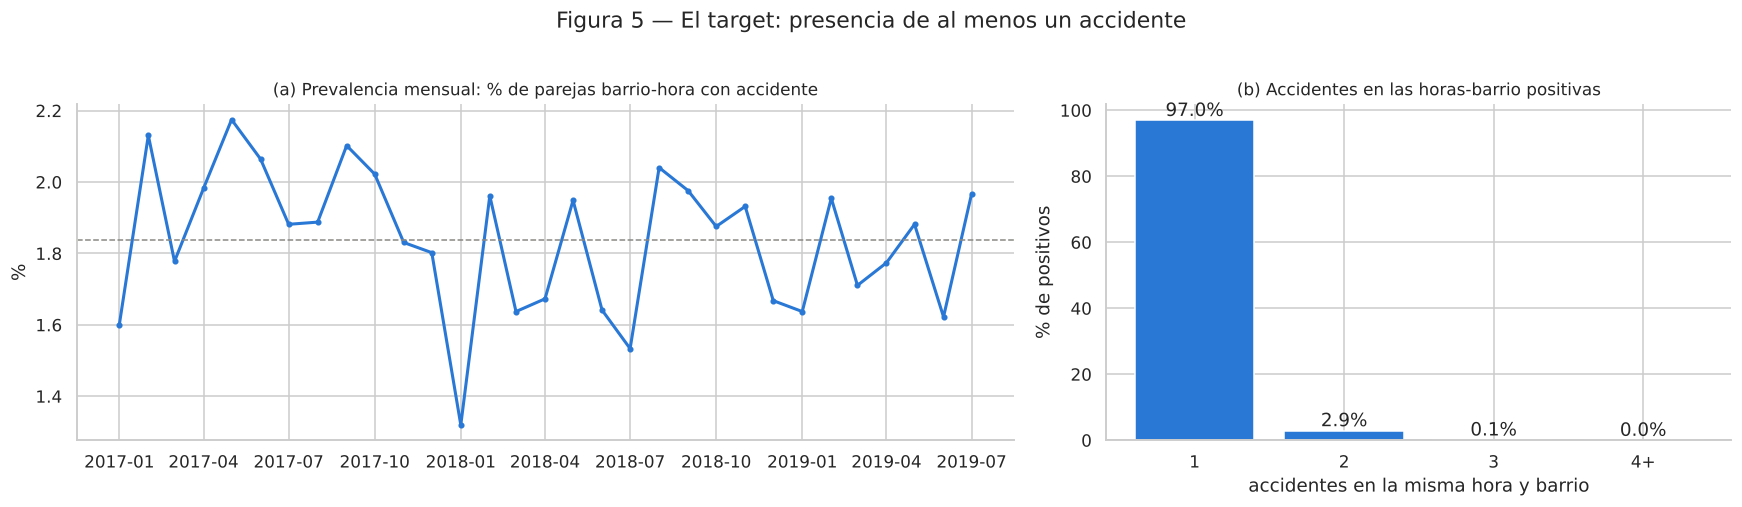

In [10]:
BARRIOS = sorted(clima.BARRIO.unique())
p = pd.MultiIndex.from_product([BARRIOS, HORAS], names=["BARRIO", "TW"]).to_frame(index=False)
p = p.merge(clima, on=["BARRIO", "TW"], how="left")
p = p.merge(acc[["BARRIO", "TW"]].assign(target=1), on=["BARRIO", "TW"], how="left")
p["target"] = p.target.fillna(0).astype("int8")
CORTE = pd.Timestamp("2019-08-01")
p.loc[p.TW >= CORTE, "target"] = -1                                    # periodo de evaluación: etiqueta oculta
n_acc = raw.groupby(["BARRIO", "TW"]).size().rename("n_acc")
p = p.join(n_acc, on=["BARRIO", "TW"])
p["n_acc"] = p.n_acc.fillna(0).astype(int)

ent = p[p.target >= 0]
consulta = pd.read_sql("SELECT BARRIO, TW FROM clima WHERE TW >= '2019-08-01 00:00:00' AND TW < '2019-12-31 00:00:00'", con)
universo = pd.Series({
    "filas de la rejilla barrio × hora (2017-2019)": len(p),
    "  · con fila en clima": len(p) - 22 * len(horas_sin_clima),
    "  · agregadas (horas sin clima)": 22 * len(horas_sin_clima),
    "entrenamiento (hasta 2019-07-31)": len(ent),
    "  · positivos (≥ 1 accidente)": int(ent.target.sum()),
    "  · prevalencia": f"{ent.target.mean():.2%}",
    "evaluación (consulta del README)": len(consulta),
})
tabla(universo.to_frame("valor"), 6, "Unidad de análisis y tamaño del problema")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[1.5, 1]))
prev = ent.groupby(ent.TW.dt.to_period("M")).target.mean() * 100
prev.index = prev.index.to_timestamp()
ax[0].plot(prev.index, prev.values, color=AZUL, lw=2, marker="o", ms=3)
ax[0].axhline(ent.target.mean() * 100, color=GRIS, ls="--", lw=1)
ax[0].set(title="(a) Prevalencia mensual: % de parejas barrio-hora con accidente", ylabel="%", xlabel="")
k = ent[ent.target == 1].n_acc.clip(upper=4).value_counts(normalize=True).sort_index() * 100
k.index = ["1", "2", "3", "4+"][: len(k)]
b = ax[1].bar(k.index, k.values, color=AZUL); ax[1].bar_label(b, fmt="%.1f%%")
ax[1].set(title="(b) Accidentes en las horas-barrio positivas", xlabel="accidentes en la misma hora y barrio", ylabel="% de positivos")
fig.suptitle("Figura 5 — El target: presencia de al menos un accidente", y=1.02)
plt.tight_layout(); plt.show()

**Lectura de la Tabla 6 y la Figura 5:**

1. La rejilla tiene 578.160 parejas: las 577.720 de `clima` más las **440 de las horas sin clima** (1.5).
2. El entrenamiento tiene **497.376 parejas con 9.138 positivas: 1.84 %**. Es el desbalance del reto (sección 6).
3. La evaluación tiene exactamente las **80.256 parejas** de la consulta del README.
4. **Figura 5a:** la prevalencia mensual oscila entre 1.3 % y 2.2 % sin tendencia clara.
5. **Figura 5b:** el **97 %** de las parejas positivas tiene un solo accidente. Un target binario pierde muy poca
   información frente a contar accidentes.

### 2.1 ¿Se corrige el target con los errores de `raw_accidentes`?

In [11]:
rc = raw.copy()
rc.loc[no_coincide, "TW"] = rc.loc[no_coincide, "TW"].dt.normalize() + pd.to_timedelta(h24[no_coincide], unit="h")
rc = rc[~fuera]
pares_corr = set(zip(rc.BARRIO, rc.TW))
efecto = pd.Series({
    "pares positivos en la tabla accidentes (oficial)": len(pares_acc),
    "pares positivos si se corrige raw": len(pares_corr),
    "pares que dejarían de ser positivos": len(pares_acc - pares_corr),
    "pares nuevos positivos": len(pares_corr - pares_acc),
    "% de positivos afectados": f"{100 * len(pares_acc ^ pares_corr) / len(pares_acc):.2f} %",
})
tabla(efecto.to_frame("valor"), 7, "Efecto de corregir raw_accidentes sobre el target")

Tabla 7 — Efecto de corregir raw_accidentes sobre el target


,valor
pares positivos en la tabla accidentes (oficial),9138
pares positivos si se corrige raw,9133
pares que dejarían de ser positivos,6
pares nuevos positivos,1
% de positivos afectados,0.08 %


**Lectura de la Tabla 7:** corregir el error AM/PM y quitar los 5 accidentes mal geocodificados cambiaría solo 7
parejas positivas (6 desaparecen y 1 aparece), el **0.08 %**.

**Decisión:** se usa la tabla `accidentes` **tal cual**. Según el README, las etiquetas ocultas del periodo de
evaluación son las filas de esa misma tabla, así que el modelo debe aprender exactamente la misma definición de
positivo que se usa para calificarlo. Las correcciones se documentan, pero no se aplican al target.

## 3. Ingeniería de características

Las tablas no traen ninguna variable de calendario (README), así que se construyen desde `TW`. Una regla guía todas
las decisiones: **toda variable debe poder calcularse para diciembre de 2019 con lo que se sabe hoy**. El calendario se
conoce con años de anticipación. Los accidentes de ago-dic 2019 no se conocen, así que no se usan lags del target
dentro del periodo a predecir.

In [12]:
FESTIVOS = pd.to_datetime("""2017-01-01 2017-01-09 2017-03-20 2017-04-13 2017-04-14 2017-05-01 2017-05-29 2017-06-19 2017-06-26
2017-07-03 2017-07-20 2017-08-07 2017-08-21 2017-10-16 2017-11-06 2017-11-13 2017-12-08 2017-12-25
2018-01-01 2018-01-08 2018-03-19 2018-03-29 2018-03-30 2018-05-01 2018-05-14 2018-06-04 2018-06-11 2018-07-02
2018-07-20 2018-08-07 2018-08-20 2018-10-15 2018-11-05 2018-11-12 2018-12-08 2018-12-25
2019-01-01 2019-01-07 2019-03-25 2019-04-18 2019-04-19 2019-05-01 2019-06-03 2019-06-24 2019-07-01 2019-07-20
2019-08-07 2019-08-19 2019-10-14 2019-11-04 2019-11-11 2019-12-08 2019-12-25""".split())

def calendario(ts):
    d = ts.dt.normalize()
    out = pd.DataFrame(index=ts.index)
    out["h"] = ts.dt.hour; out["dow"] = ts.dt.dayofweek; out["mes"] = ts.dt.month
    out["doy"] = ts.dt.dayofyear; out["dom"] = ts.dt.day
    fest = d.isin(FESTIVOS)
    out["festivo"] = fest.astype(int)
    out["tipo_dia"] = np.where(fest, 6, out.dow)                          # un festivo se comporta como domingo
    out["vispera"] = (d + pd.Timedelta(days=1)).isin(FESTIVOS).astype(int)
    out["lunes_fest"] = (fest & (out.dow == 0)).astype(int)               # puente (Ley Emiliani)
    out["quincena"] = out.dom.isin([14, 15, 16, 29, 30, 31, 1]).astype(int)
    out["dic_ene"] = (((out.mes == 12) & (out.dom >= 15)) | ((out.mes == 1) & (out.dom <= 10))).astype(int)
    out["feria"] = ((out.mes == 8) & (out.dom <= 12)).astype(int)         # Feria de las Flores
    out["t"] = (ts - pd.Timestamp("2017-01-01")).dt.days / 365.0          # tendencia, en años
    out["hs"] = np.sin(2 * np.pi * out.h / 24); out["hc"] = np.cos(2 * np.pi * out.h / 24)
    out["ys"] = np.sin(2 * np.pi * out.doy / 365.25); out["yc"] = np.cos(2 * np.pi * out.doy / 365.25)
    return out

p = pd.concat([p, calendario(p.TW)], axis=1)
p["barrio"] = p.BARRIO.astype("category")                                # categórica nativa de LightGBM
ent = p[p.target >= 0]
print(f"Festivos en la lista: {len(FESTIVOS)} ({FESTIVOS.year.value_counts().sort_index().to_dict()})")

desc = pd.DataFrame([
    ["barrio", "categórica (22)", "nombre del barrio", "los accidentes varían 14 veces entre barrios (Figura 2a)"],
    ["h, dow, mes, doy", "enteras", "hora, día de la semana, mes y día del año de TW", "el perfil horario domina (Figura 1b)"],
    ["festivo, tipo_dia", "binaria / 0-6", "festivo de Colombia; tipo_dia = día de semana, con festivo = 6", "un festivo apaga la hora pico (Figura 6a)"],
    ["vispera, lunes_fest", "binarias", "víspera de festivo; lunes festivo (puente)", "cambian la movilidad del día"],
    ["quincena", "binaria", "días 14-16 y 29-1", "días de pago"],
    ["dic_ene, feria", "binarias", "15-dic a 10-ene; 1-12 de agosto", "temporadas especiales del calendario"],
    ["t", "continua", "años desde 2017-01-01", "deja ver el cambio lento de cada barrio"],
    ["hs, hc, ys, yc", "continuas", "seno y coseno de la hora y del día del año", "codificación cíclica (se compara en 5.2)"],
], columns=["variable", "tipo", "cómo se calcula", "por qué"])
tabla(desc, 8, "Variables creadas a partir de TW")

Festivos en la lista: 53 ({2017: 18, 2018: 18, 2019: 17})
Tabla 8 — Variables creadas a partir de TW


,variable,tipo,cómo se calcula,por qué
0,barrio,categórica (22),nombre del barrio,los accidentes varían 14 veces entre barrios (Figura 2a)
1,"h, dow, mes, doy",enteras,"hora, día de la semana, mes y día del año de TW",el perfil horario domina (Figura 1b)
2,"festivo, tipo_dia",binaria / 0-6,"festivo de Colombia; tipo_dia = día de semana, con festivo = 6",un festivo apaga la hora pico (Figura 6a)
3,"vispera, lunes_fest",binarias,víspera de festivo; lunes festivo (puente),cambian la movilidad del día
4,quincena,binaria,días 14-16 y 29-1,días de pago
5,"dic_ene, feria",binarias,15-dic a 10-ene; 1-12 de agosto,temporadas especiales del calendario
6,t,continua,años desde 2017-01-01,deja ver el cambio lento de cada barrio
7,"hs, hc, ys, yc",continuas,seno y coseno de la hora y del día del año,codificación cíclica (se compara en 5.2)


**Codificación (Tabla 8):**

1. **Categórica:** `barrio` entra como categórica nativa de LightGBM, que agrupa barrios en cada división sin crear 22
   columnas. En la logística (5.2) se usa *one-hot*.
2. **Cíclicas:** la hora 23 y la hora 0 son vecinas, pero como entero están en los extremos. El seno y el coseno las
   ponen juntas (Figura 6c). Un árbol no lo necesita, porque corta la hora en intervalos (por ejemplo, "h ≥ 6 y h < 19").
   Por eso se calculan y se **comparan** en 5.2, pero no entran en el modelo final.
3. **Festivos:** la lista de festivos de Colombia 2017-2019 (53 días) incluye los trasladados a lunes por la Ley Emiliani
   y la Semana Santa.

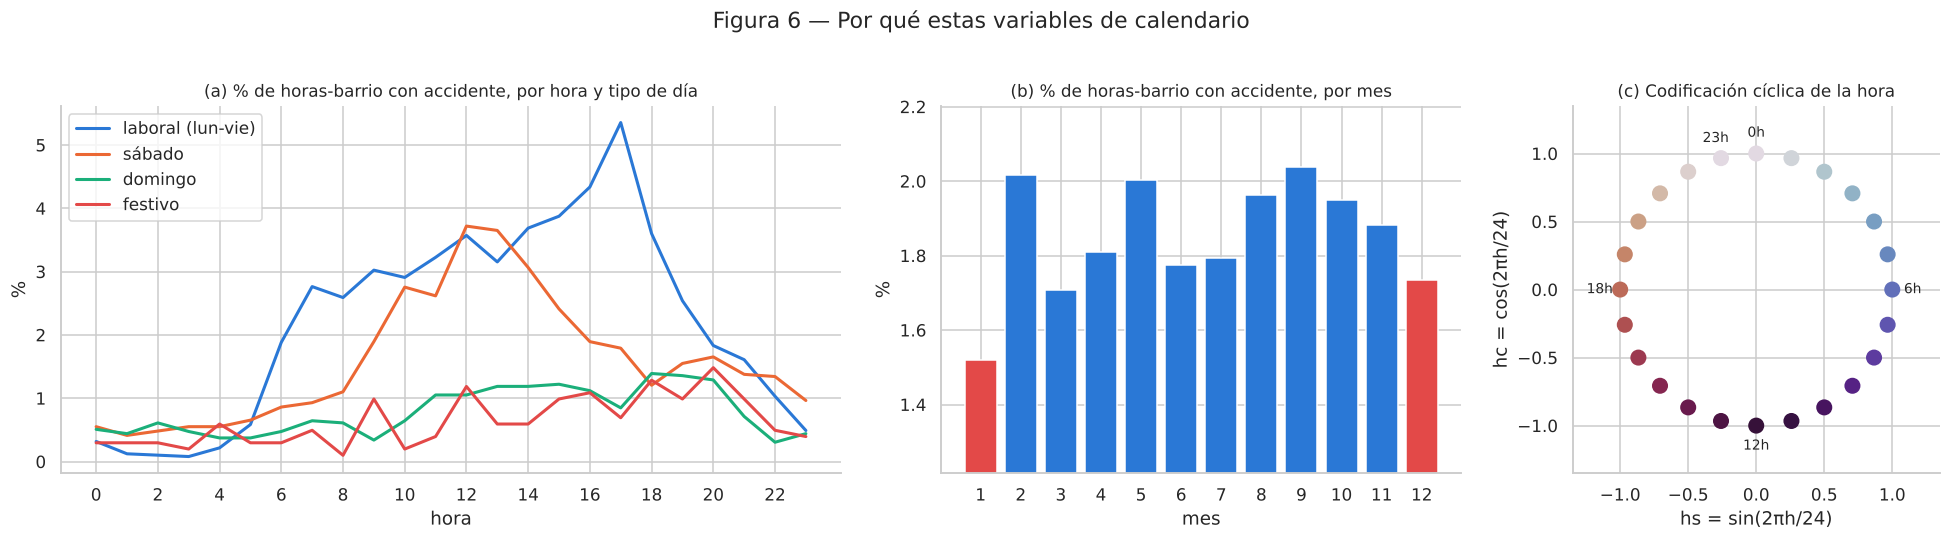

Hora pico laboral: 17 h con 5.35 % | misma hora en festivo: 0.69 %
A las 8 h: laboral 2.59 % vs festivo 0.1 %


In [13]:
TIPO = np.select([ent.festivo == 1, ent.dow == 6, ent.dow == 5], ["festivo", "domingo", "sábado"], "laboral (lun-vie)")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw=dict(width_ratios=[1.5, 1, 0.75]))
perfil = ent.assign(tipo=TIPO).groupby(["tipo", "h"]).target.mean().unstack(0) * 100
for col, c in zip(["laboral (lun-vie)", "sábado", "domingo", "festivo"], [AZUL, NARANJA, VERDE, ROJO]):
    ax[0].plot(perfil.index, perfil[col], color=c, lw=2, label=col)
ax[0].set(title="(a) % de horas-barrio con accidente, por hora y tipo de día", xlabel="hora", ylabel="%")
ax[0].set_xticks(range(0, 24, 2)); ax[0].legend()
mes = ent.groupby("mes").target.mean() * 100
b = ax[1].bar(mes.index, mes.values, color=[ROJO if i in (1, 12) else AZUL for i in mes.index])
ax[1].set(title="(b) % de horas-barrio con accidente, por mes", xlabel="mes", ylabel="%", ylim=(mes.min() * .8, mes.max() * 1.08))
ax[1].set_xticks(range(1, 13))
hh = np.arange(24)
sc = ax[2].scatter(np.sin(2 * np.pi * hh / 24), np.cos(2 * np.pi * hh / 24), c=hh, cmap="twilight", s=90)
for i in (0, 6, 12, 18, 23):
    ax[2].annotate(f"{i}h", (np.sin(2 * np.pi * i / 24) * 1.15, np.cos(2 * np.pi * i / 24) * 1.15), ha="center", va="center", fontsize=9)
ax[2].set(title="(c) Codificación cíclica de la hora", xlabel="hs = sin(2πh/24)", ylabel="hc = cos(2πh/24)", aspect="equal",
          xlim=(-1.35, 1.35), ylim=(-1.35, 1.35))
fig.suptitle("Figura 6 — Por qué estas variables de calendario", y=1.02)
plt.tight_layout(); plt.show()
print("Hora pico laboral:", perfil["laboral (lun-vie)"].idxmax(), "h con", round(perfil["laboral (lun-vie)"].max(), 2),
      "% | misma hora en festivo:", round(perfil.loc[perfil["laboral (lun-vie)"].idxmax(), "festivo"], 2), "%")
print("A las 8 h: laboral", round(perfil.loc[8, "laboral (lun-vie)"], 2), "% vs festivo", round(perfil.loc[8, "festivo"], 2), "%")

**Lectura de la Figura 6 (por qué estas variables):**

1. **(a) El tipo de día cambia la forma del día, no solo su nivel.** Un día laboral tiene su pico a las 17 h (5.35 %
   de las horas-barrio con accidente). Un festivo a esa misma hora tiene 0.69 %, y a las 8 h pasa de 2.59 % a 0.10 %.
   El festivo se parece a un domingo, por eso `tipo_dia` lo codifica como día 6.
2. **(b) Temporada:** enero (1.5 %) y diciembre (1.7 %) son los meses de menor riesgo, por las vacaciones (barras rojas,
   variable `dic_ene`).
3. **(c) Codificación cíclica** de la hora: las 23 h quedan junto a las 0 h.

## 4. Validación

**Partición temporal walk-forward con ventana expansiva** (diapositivas, sección de series de tiempo). Cada corte
entrena con **todo** lo anterior a una fecha y valida en los **5 meses siguientes**: el mismo horizonte de la entrega
(ago-dic 2019). Se usan 6 cortes entre jul-2018 y mar-2019. Uno de ellos (2018-08) evalúa la misma temporada del
leaderboard.

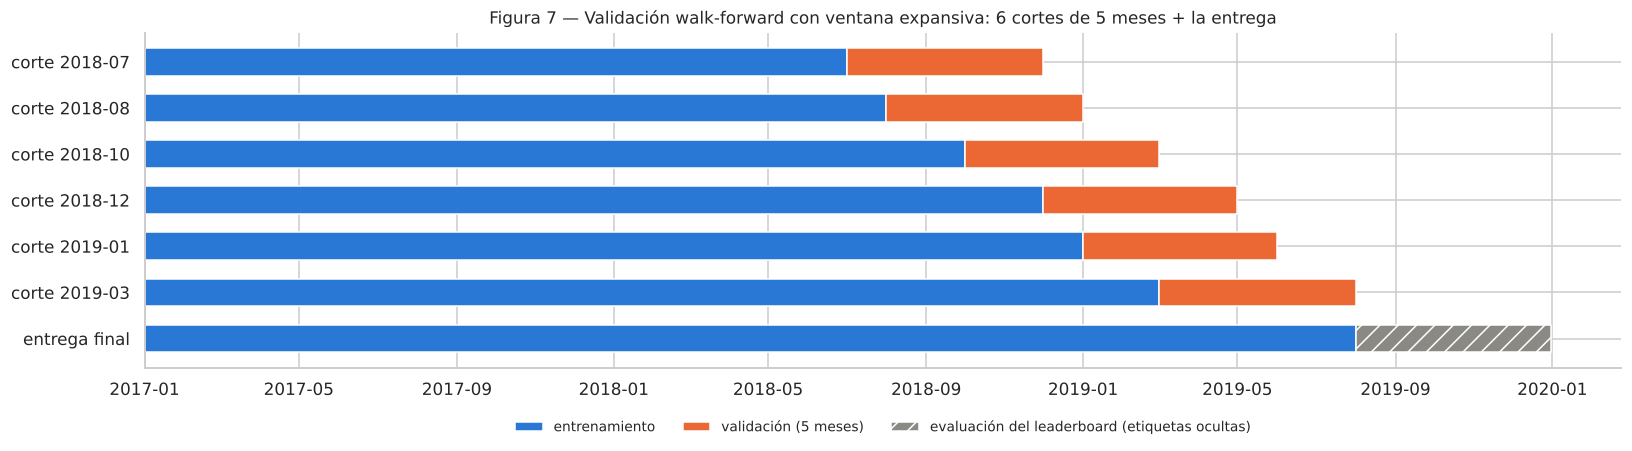

Tabla 9 — Los 6 cortes de validación (cada uno evalúa todas las parejas barrio × hora del periodo)


,corte,entrena hasta,valida,filas validación,positivos
0,2018-07,2018-06-30 23:00:00,2018-07-01 a 2018-11-30,80784,1511
1,2018-08,2018-07-31 23:00:00,2018-08-01 a 2018-12-31,80784,1533
2,2018-10,2018-09-30 23:00:00,2018-10-01 a 2019-02-28,79728,1443
3,2018-12,2018-11-30 23:00:00,2018-12-01 a 2019-04-30,79728,1391
4,2019-01,2018-12-31 23:00:00,2019-01-01 a 2019-05-31,79728,1426
5,2019-03,2019-02-28 23:00:00,2019-03-01 a 2019-07-31,80784,1448


In [14]:
CORTES = ["2018-07-01", "2018-08-01", "2018-10-01", "2018-12-01", "2019-01-01", "2019-03-01"]
HORIZONTE = pd.DateOffset(months=5)                                       # igual que ago-dic 2019

def fold(c):
    a = pd.Timestamp(c)
    return p[(p.TW < a) & (p.target >= 0)], p[(p.TW >= a) & (p.TW < a + HORIZONTE)]

fig, ax = plt.subplots(figsize=(15, 4.3))
filas = [(c[:7], pd.Timestamp(c), pd.Timestamp(c) + HORIZONTE, False) for c in CORTES] + [("entrega", CORTE, pd.Timestamp("2019-12-31"), True)]
for i, (nom, a, b, oculto) in enumerate(filas):
    ax.barh(i, mdates.date2num(a) - mdates.date2num(pd.Timestamp("2017-01-01")), left=mdates.date2num(pd.Timestamp("2017-01-01")),
            color=AZUL, height=.6, label="entrenamiento" if i == 0 else None)
    ax.barh(i, mdates.date2num(b) - mdates.date2num(a), left=mdates.date2num(a), height=.6,
            color=GRIS if oculto else NARANJA, hatch="//" if oculto else None, edgecolor="white",
            label=("evaluación del leaderboard (etiquetas ocultas)" if oculto else ("validación (5 meses)" if i == 0 else None)))
ax.set_yticks(range(len(filas)), [f"corte {f[0]}" if not f[3] else "entrega final" for f in filas])
ax.invert_yaxis(); ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9, frameon=False)
ax.set(title="Figura 7 — Validación walk-forward con ventana expansiva: 6 cortes de 5 meses + la entrega")
plt.tight_layout(); plt.show()

val = pd.DataFrame([dict(corte=c[:7], **{"entrena hasta": fold(c)[0].TW.max(), "valida": f"{fold(c)[1].TW.min():%Y-%m-%d} a {fold(c)[1].TW.max():%Y-%m-%d}",
                                         "filas validación": len(fold(c)[1]), "positivos": int(fold(c)[1].target.sum())}) for c in CORTES])
tabla(val, 9, "Los 6 cortes de validación (cada uno evalúa todas las parejas barrio × hora del periodo)")

**Lectura de la Figura 7 y la Tabla 9:**

1. Cada corte entrena solo con el pasado (barra azul) y se evalúa en las **79.728 a 80.784 parejas** de sus 5 meses
   (barra naranja), con entre 1.391 y 1.533 positivos. La evaluación es siempre el periodo completo, con su desbalance
   real.
2. La última fila es la entrega: entrena hasta el 2019-07-31 y predice ago-dic 2019, que el leaderboard califica.
3. **Expansiva y no deslizante:** en una exploración previa, entrenar solo con los últimos 6, 12 o 18 meses dio 0.7765,
   0.7816 y 0.7824, frente a **0.7842** con todo el historial (5.3). Con 1.84 % de positivos, cada año extra de datos
   pesa más que adaptarse al cambio reciente.

**¿Por qué una partición aleatoria sería un error?** Se compara el mismo modelo con las dos particiones.

In [15]:
VARIABLES = ["barrio", "h", "dow", "tipo_dia", "mes", "doy", "festivo", "vispera", "lunes_fest", "quincena", "dic_ene", "feria", "t"]
PARAMS = dict(n_estimators=400, learning_rate=0.02, num_leaves=15, min_child_samples=400, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.7, reg_lambda=5, random_state=SEED, verbose=-1)
lgbm = lambda d, F=VARIABLES: lgb.LGBMClassifier(**PARAMS).fit(d[F], d.target)

dev = p[p.target >= 0]
tr_r, va_r = train_test_split(dev, test_size=0.2, random_state=SEED, stratify=dev.target)
auc_aleat = roc_auc_score(va_r.target, lgbm(tr_r).predict_proba(va_r[VARIABLES])[:, 1])
tr_t, va_t = fold("2019-03-01")
auc_temp = roc_auc_score(va_t.target, lgbm(tr_t).predict_proba(va_t[VARIABLES])[:, 1])
tabla(pd.DataFrame({"ROC-AUC": [auc_aleat, auc_temp], "¿el modelo vio el futuro?": ["sí: entrena con días posteriores a los que evalúa", "no"]},
                   index=["partición aleatoria 80/20 (todo 2017 a jul-2019)", "partición temporal (corte 2019-03)"]).round(4),
      10, "Mismo modelo, dos formas de partir los datos")

Tabla 10 — Mismo modelo, dos formas de partir los datos


,ROC-AUC,¿el modelo vio el futuro?
partición aleatoria 80/20 (todo 2017 a jul-2019),0.8016,sí: entrena con días posteriores a los que evalúa
partición temporal (corte 2019-03),0.7790,no


**Lectura de la Tabla 10:** con partición aleatoria el modelo saca **0.8016**, con temporal **0.7790**. La aleatoria
infla el resultado en **+0.023**. El modelo entrena con horas posteriores a las que evalúa, y con la variable de
tendencia `t` puede aprender el nivel de cada barrio en esas mismas semanas. En el leaderboard nunca tiene esa información: la
partición aleatoria promete un resultado que no se cumple.

## 5. Modelado

### 5.1 ¿Dónde está la señal? Prueba de oráculos

Antes de elegir modelo, una pregunta de fondo: ¿ayudaría saber cuántos accidentes **habrá** ese día, esa semana o ese
mes? Es lo que intentaría un modelo de series de tiempo como **Prophet**, que pronostica el nivel diario con tendencia y
festivos. Para responderla, se hace trampa a propósito: se toma una base simple (tasa barrio × hora × perfil del día de
la semana) y se le da el **número real** de accidentes de ese día, semana o mes en el periodo de validación, **sin contar
la propia fila**. Si ni siquiera con el nivel real se gana, un pronóstico de ese nivel tampoco puede ganar.

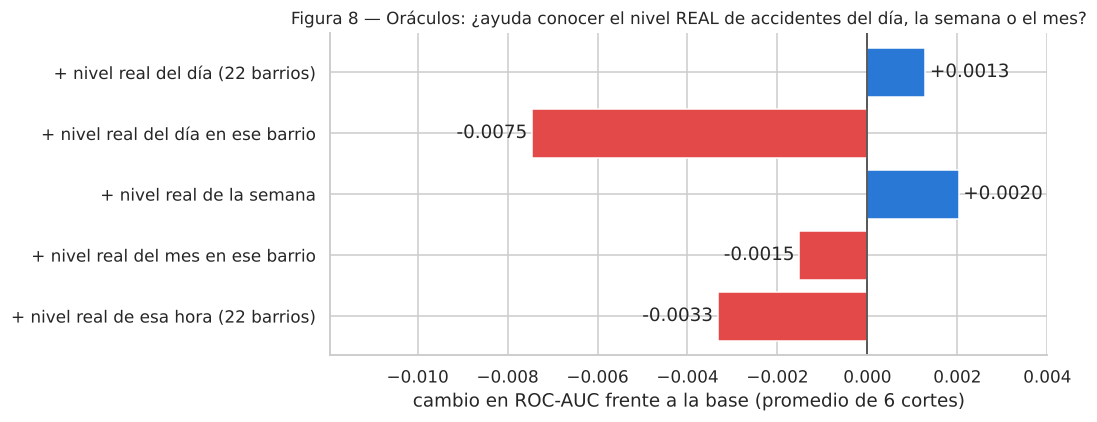

Tabla 11 — ROC-AUC de la base y de la base ajustada con niveles reales (sin la propia fila)


,base: barrio × hora × día,+ nivel real del día (22 barrios),+ nivel real del día en ese barrio,+ nivel real de la semana,+ nivel real del mes en ese barrio,+ nivel real de esa hora (22 barrios)
corte,,,,,,
2018-07,0.7783,0.7778,0.7750,0.7778,0.7761,0.7745
2018-08,0.7751,0.7744,0.7699,0.7755,0.7705,0.7703
2018-10,0.7762,0.7774,0.7690,0.7786,0.7738,0.7735
2018-12,0.7651,0.7675,0.7556,0.7689,0.7643,0.7622
2019-01,0.7636,0.7667,0.7532,0.7677,0.7644,0.7627
2019-03,0.7605,0.7628,0.7513,0.7625,0.7606,0.7556
promedio,0.7698,0.7711,0.7623,0.7718,0.7683,0.7665


In [16]:
ORACULOS = {"nivel real del día (22 barrios)": ["d"], "nivel real del día en ese barrio": ["d", "BARRIO"],
            "nivel real de la semana": ["sem"], "nivel real del mes en ese barrio": ["mes", "BARRIO"],
            "nivel real de esa hora (22 barrios)": ["TW"]}
filas = []
for c in CORTES:
    tr, va = fold(c)
    va = va.assign(d=va.TW.dt.normalize(), sem=va.TW.dt.to_period("W").astype(str))
    base = tr.groupby(["BARRIO", "h"]).target.mean()
    prof = tr.groupby(["dow", "h"]).target.mean() / tr.target.mean()
    va["base"] = va.set_index(["BARRIO", "h"]).index.map(base).values * va.set_index(["dow", "h"]).index.map(prof).values
    fila = {"corte": c[:7], "base: barrio × hora × día": roc_auc_score(va.target, va.base)}
    for nom, key in ORACULOS.items():
        obs = va.groupby(key).n_acc.transform("sum") - va.n_acc           # se excluye la propia fila
        esp = va.groupby(key).base.transform("sum") - va.base
        fila["+ " + nom] = roc_auc_score(va.target, va.base * (obs + 1) / (esp + 1))
    filas.append(fila)
orac = pd.DataFrame(filas).set_index("corte")
orac.loc["promedio"] = orac.mean()
ganancia = (orac.loc["promedio"] - orac.loc["promedio", "base: barrio × hora × día"]).drop("base: barrio × hora × día")

fig, ax = plt.subplots(figsize=(10, 4))
b = ax.barh(ganancia.index[::-1], ganancia.values[::-1], color=[ROJO if g < 0 else AZUL for g in ganancia.values[::-1]])
ax.bar_label(b, fmt="%+.4f", padding=3); ax.axvline(0, color="#333", lw=1)
ax.set(xlabel="cambio en ROC-AUC frente a la base (promedio de 6 cortes)", xlim=(min(ganancia.min() * 1.6, -0.003), 0.004),
       title="Figura 8 — Oráculos: ¿ayuda conocer el nivel REAL de accidentes del día, la semana o el mes?")
plt.tight_layout(); plt.show()
tabla(orac.round(4), 11, "ROC-AUC de la base y de la base ajustada con niveles reales (sin la propia fila)")

**Lectura de la Figura 8 y la Tabla 11:**

1. Conocer el nivel **real** del día o de la semana sube el ROC-AUC apenas **+0.0013** y **+0.0020**. Y eso con
   información perfecta, que nunca se tiene.
2. El nivel real del día en ese barrio, del mes en ese barrio o de esa hora en la comuna **empeora** el resultado
   (−0.0015 a −0.0075). Con tan pocos accidentes, esos niveles son sobre todo ruido.

**Conclusión:** la señal no está en *cuántos* accidentes habrá en un periodo, sino en **dónde y a qué hora**, es
decir en la estructura barrio × hora × tipo de día. Eso explica por qué Prophet, la tendencia por barrio y el clima no
mejoraron el modelo (5.3), y orienta la búsqueda hacia un modelo que capture esa estructura.

### 5.2 La escalera de modelos

Se parte del `groupby` del README y en cada paso se agrega una sola idea, evaluando siempre en los mismos 6 cortes:

| Paso | Idea que agrega |
|---|---|
| M0 | Tasa histórica barrio × hora (la referencia del README) |
| M1 | + tipo de día, con suavizado hacia la tasa barrio × hora (las celdas tienen pocos datos) |
| M2 | Modelo lineal: logística L2 con interacciones barrio × hora, barrio × tipo de día y hora × tipo de día, más el calendario |
| M3 | **LightGBM global**: un solo modelo para los 22 barrios, que aprende las interacciones solo |
| M4 | + tendencia `t` (cambio lento de cada barrio) → **modelo final** |
| M4 + … | Tres ideas que se probaron y se descartaron: clima, lag de 52 semanas, codificación cíclica |

In [17]:
for a_, b_ in [("BARRIO", "h"), ("BARRIO", "tipo_dia"), ("h", "tipo_dia")]:
    p[f"{a_}_{b_}"] = p[a_].astype(str) + "_" + p[b_].astype(str)
y_lag = p.target.where(p.target >= 0).astype(float)
p["lag52"] = y_lag.groupby(p.BARRIO).shift(52 * 7 * 24)                  # misma hora y día de la semana, 52 semanas antes
CLIMA_F = ["precipIntensity", "temperature", "humidity", "windSpeed", "cloudCover", "visibility"]
LOG_F = ["BARRIO", "h", "tipo_dia", "mes", "festivo", "vispera", "lunes_fest", "quincena", "dic_ene", "feria",
         "BARRIO_h", "BARRIO_tipo_dia", "h_tipo_dia"]

def tasa_bh(tr, va):
    return va.set_index(["BARRIO", "h"]).index.map(tr.groupby(["BARRIO", "h"]).target.mean()).values

def tasa_bht(tr, va, m=100):
    prior = tasa_bh(tr, va)
    st = tr.groupby(["BARRIO", "h", "tipo_dia"]).target.agg(["sum", "count"])
    k = pd.MultiIndex.from_frame(va[["BARRIO", "h", "tipo_dia"]])
    return (st["sum"].reindex(k).fillna(0).values + m * prior) / (st["count"].reindex(k).fillna(0).values + m)

def logistica(tr, va):
    enc = OneHotEncoder(handle_unknown="ignore").fit(tr[LOG_F].astype(str))
    m = LogisticRegression(C=0.03, max_iter=2000).fit(enc.transform(tr[LOG_F].astype(str)), tr.target)
    return m.predict_proba(enc.transform(va[LOG_F].astype(str)))[:, 1]

def con_lgbm(F):
    return lambda tr, va: lgbm(tr, F).predict_proba(va[F])[:, 1]

ESCALERA = {
    "M0 · tasa histórica barrio × hora": tasa_bh,
    "M1 · tasa barrio × hora × tipo de día": tasa_bht,
    "M2 · logística L2 con interacciones": logistica,
    "M3 · LightGBM: barrio + calendario": con_lgbm([v for v in VARIABLES if v != "t"]),
    "M4 · LightGBM: barrio + calendario + t (FINAL)": con_lgbm(VARIABLES),
    "M4 + clima": con_lgbm(VARIABLES + CLIMA_F),
    "M4 + lag de 52 semanas": con_lgbm(VARIABLES + ["lag52"]),
    "M4 + codificación cíclica": con_lgbm(VARIABLES + ["hs", "hc", "ys", "yc"]),
}
PRED, filas = {}, []
for c in CORTES:
    tr, va = fold(c)
    for nom, f in ESCALERA.items():
        PRED[nom, c] = f(tr, va)
        filas.append(dict(modelo=nom, corte=c[:7], auc=roc_auc_score(va.target, PRED[nom, c])))
res = pd.DataFrame(filas).pivot(index="modelo", columns="corte", values="auc").loc[list(ESCALERA)]
res["promedio"] = res.mean(axis=1); res["mín"] = res.iloc[:, :6].min(axis=1); res["máx"] = res.iloc[:, :6].max(axis=1)
tabla(res.round(4), 12, "ROC-AUC por corte de validación (6 cortes walk-forward)")

Tabla 12 — ROC-AUC por corte de validación (6 cortes walk-forward)


corte,2018-07,2018-08,2018-10,2018-12,2019-01,2019-03,promedio,mín,máx
modelo,,,,,,,,,
M0 · tasa histórica barrio × hora,0.7653,0.7618,0.7642,0.7576,0.7594,0.7553,0.7606,0.7553,0.7653
M1 · tasa barrio × hora × tipo de día,0.7682,0.7658,0.7682,0.7613,0.7628,0.7607,0.7645,0.7607,0.7682
M2 · logística L2 con interacciones,0.7808,0.7799,0.7851,0.7830,0.7797,0.7762,0.7808,0.7762,0.7851
M3 · LightGBM: barrio + calendario,0.7845,0.7833,0.7887,0.7850,0.7839,0.7793,0.7841,0.7793,0.7887
M4 · LightGBM: barrio + calendario + t (FINAL),0.7841,0.7836,0.7894,0.7857,0.7850,0.7790,0.7845,0.7790,0.7894
M4 + clima,0.7814,0.7803,0.7877,0.7851,0.7830,0.7784,0.7827,0.7784,0.7877
M4 + lag de 52 semanas,0.7842,0.7832,0.7902,0.7861,0.7850,0.7792,0.7847,0.7792,0.7902
M4 + codificación cíclica,0.7846,0.7842,0.7910,0.7862,0.7848,0.7792,0.7850,0.7792,0.7910


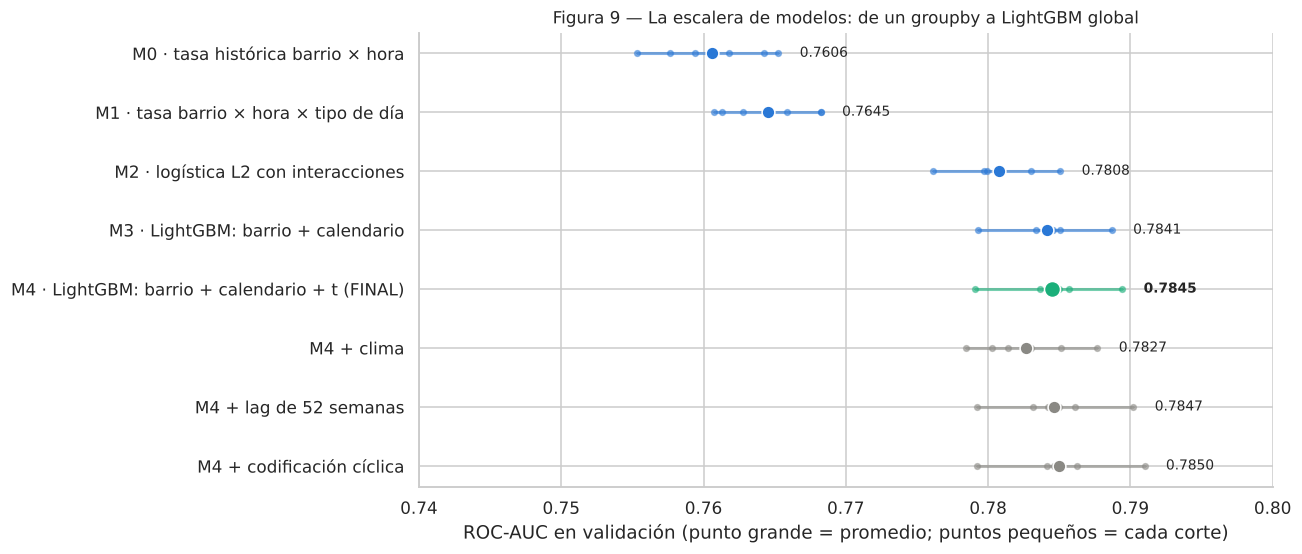

In [18]:
fig, ax = plt.subplots(figsize=(12, 5.2))
orden = list(ESCALERA)[::-1]
for i, nom in enumerate(orden):
    final = "FINAL" in nom
    c = VERDE if final else (GRIS if nom.startswith("M4 +") else AZUL)
    ax.plot([res.loc[nom, "mín"], res.loc[nom, "máx"]], [i, i], color=c, lw=2, alpha=.6)
    ax.scatter(res.loc[nom, res.columns[:6]], [i] * 6, color=c, s=14, alpha=.5)
    ax.scatter(res.loc[nom, "promedio"], i, color=c, s=110 if final else 70, zorder=3, edgecolor="white")
    ax.text(res.loc[nom, "máx"] + 0.0015, i, f"{res.loc[nom, 'promedio']:.4f}", va="center", fontsize=9,
            fontweight="bold" if final else "normal")
ax.set_yticks(range(len(orden)), orden)
ax.set(xlabel="ROC-AUC en validación (punto grande = promedio; puntos pequeños = cada corte)", xlim=(0.74, 0.80),
       title="Figura 9 — La escalera de modelos: de un groupby a LightGBM global")
plt.tight_layout(); plt.show()

**Lectura de la Tabla 12 y la Figura 9:**

1. **M0 → M1 (0.7606 → 0.7645):** el `groupby` reproduce la referencia del README (0.7589 en el leaderboard). Agregar
   el tipo de día ayuda, pero las celdas barrio × hora × día tienen 2 o 3 accidentes en promedio y el promedio simple
   se queda corto.
2. **M1 → M2 (0.7808):** la logística con interacciones suma el calendario completo y ya queda por encima del valor
   del baseline del profesor (0.7739, medido en el leaderboard).
3. **M2 → M3 (0.7841):** **LightGBM global** gana en los 6 cortes. Es la recomendación de las diapositivas para
   *muchas series relacionadas*: un **modelo global** que aprende lo común (hora pico, festivos, temporada) con los
   9.138 positivos juntos, y usa `barrio` para lo propio de cada barrio. Las interacciones no hay que escribirlas a
   mano: los árboles las encuentran.
4. **M3 → M4 (0.7845):** la tendencia `t` agrega un poco más, y es el **modelo final**. Rango entre cortes:
   0.7790–0.7894.
5. **Descartes:**
   - **El clima empeora** (0.7827): confirma 1.6.
   - **El lag de 52 semanas** (0.7847) y **la codificación cíclica** (0.7850) quedan +0.0002 y +0.0005 por encima de M4.
     Es una diferencia muy chica frente a lo que varía M4 entre cortes (0.010) y frente al rango por azar de un periodo
     de 5 meses (±0.012, sección 8), así que es ruido. Se mantuvo M4, el modelo elegido y entregado antes de esta
     comparación.

**¿Por qué LightGBM?** (1) Hay 22 series con pocos positivos cada una, y un modelo global comparte información entre
ellas. (2) Captura interacciones no lineales (un festivo apaga la hora pico, Figura 6a) sin especificarlas. (3) Maneja
`barrio` como categórica nativa. (4) Entrena en segundos sobre medio millón de filas.

### 5.3 Lo que probamos y no funcionó

Estas ideas se midieron en exploraciones previas con la misma validación walk-forward, usando scripts del repositorio.
No se re-ejecutan aquí para no alargar el notebook. Cada fila compara con la referencia **de ese mismo experimento**.

| Idea | Qué se probó | ROC-AUC (referencia) | Por qué no funcionó |
|---|---|---|---|
| **Prophet** por barrio | Pronóstico del nivel diario de cada barrio (festivos de Colombia, estacionalidad semanal y anual) como variable de LightGBM | 0.7614 (0.7811) | El nivel diario no aporta (5.1). La serie diaria por barrio es 68 % ceros, y Prophet asume ruido gaussiano |
| Ventana deslizante | Entrenar solo con los últimos 6 / 12 / 18 meses | 0.7765 / 0.7816 / 0.7824 (0.7842) | Con 1.8 % de positivos, perder historia cuesta más que adaptarse al cambio |
| Lags estacionales | Target de 52 y 104 semanas antes, puntual y suavizado | 0.7841–0.7846 (0.7842) | Un barrio-hora concreto tiene ~2 % de probabilidad: su valor de hace un año es casi un volado |
| *Target encoding* | barrio × mes y barrio × tipo de día, fuera de muestra por trimestre | 0.7838–0.7844 (0.7842) | LightGBM ya aprende esas interacciones |
| Variables espaciales | Centroide, % en intersección o glorieta, % con heridos, tasa de los 3 barrios vecinos | 0.7835 (0.7842) | `barrio` ya identifica todo lo estático |
| Clima diario | Lluvia del día, lluvia de las 1/3/6 h previas | 0.7828–0.7839 (0.7842) | Igual en los 22 barrios y sin señal propia (1.6) |
| Ensamble | Logística + LightGBM, promedio de rangos | 0.7841 (0.7842) | Los dos modelos ven la misma estructura: se equivocan en lo mismo |
| Optuna | 40 intentos (TPE), con un corte de prueba limpio que la búsqueda no veía | 0.7786 (0.7791) | El modelo es poco sensible a los hiperparámetros; la ganancia en ajuste era ruido |
| Objetivo Poisson | Predecir el número de accidentes | 0.7840 (0.7842) | El 97 % de los positivos tiene un solo accidente (Figura 5b) |
| *Bagging* | 20 LightGBM con *bootstrap* por semanas | 0.7841 (0.7842) | LightGBM regularizado ya tiene poca varianza |
| Pendiente por barrio | Tendencia propia de cada barrio (Poisson mensual) + Optuna | 0.7842–0.7846 (0.7851) | Unos 20 puntos mensuales por barrio, ruidosos; extrapolar 5 meses empeora |
| **Un modelo por barrio** | 22 LightGBM locales (complejidad fija y ajustada), estandarizados al nivel del global, y en ensamble con el global | 0.7690–0.7746 (0.7851) | Cada barrio tiene ~400 positivos: el modelo local aprende ruido. El ensamble con el global solo empeora a medida que pesa más el local |

## 6. Manejo del desbalance

Con 1.84 % de positivos se compararon las técnicas de balanceo de clase sobre el modelo final, en los cortes 2018-08 y
2019-03. Se evalúan tres cosas: ROC-AUC, PR-AUC y **la probabilidad media que predice el modelo**, porque una
probabilidad bien calibrada es la que permite fijar un umbral con costos reales (6.1).

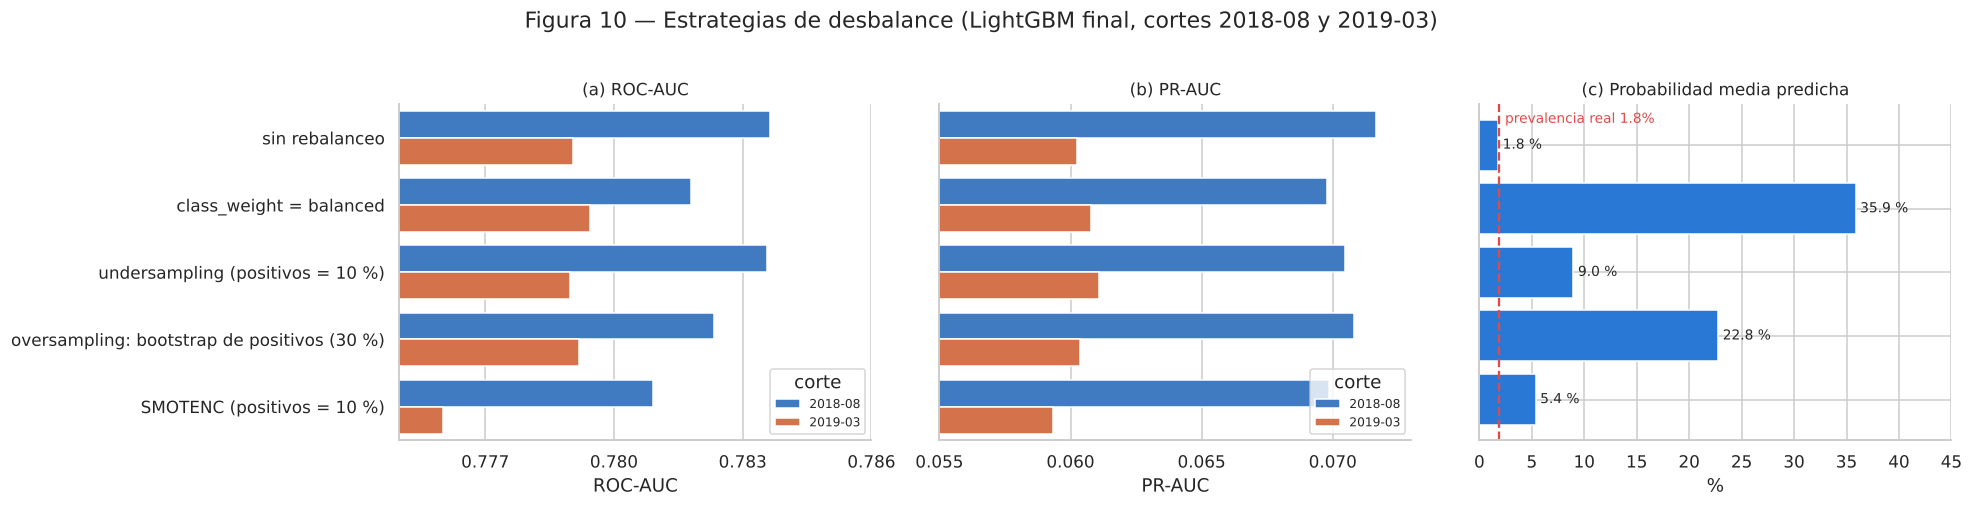

Tabla 13 — Estrategias de desbalance, promedio de los dos cortes


,ROC-AUC,PR-AUC,prob. media predicha,prevalencia real
estrategia,,,,
sin rebalanceo,0.7813,0.0659,0.0178,0.0185
class_weight = balanced,0.7806,0.0653,0.3587,0.0185
undersampling (positivos = 10 %),0.7813,0.0658,0.0896,0.0185
oversampling: bootstrap de positivos (30 %),0.7808,0.0656,0.2277,0.0185
SMOTENC (positivos = 10 %),0.7785,0.0646,0.0536,0.0185


In [19]:
CORTES_D = ["2018-08-01", "2019-03-01"]
CAT_IDX = [i for i, v in enumerate(VARIABLES) if v not in ("doy", "t")]

def estrategia(nombre, tr):
    rng = np.random.default_rng(SEED)
    pos, neg = tr[tr.target == 1], tr[tr.target == 0]
    if nombre == "sin rebalanceo":
        return lgbm(tr)
    if nombre == "class_weight = balanced":
        return lgb.LGBMClassifier(**PARAMS, class_weight="balanced").fit(tr[VARIABLES], tr.target)
    if nombre == "undersampling (positivos = 10 %)":
        d = pd.concat([pos, neg.iloc[rng.choice(len(neg), 9 * len(pos), replace=False)]])
    if nombre == "oversampling: bootstrap de positivos (30 %)":
        d = pd.concat([neg, pos.iloc[rng.integers(0, len(pos), int(0.3 * len(neg) / 0.7))]])
    if nombre == "SMOTENC (positivos = 10 %)":
        X = tr[VARIABLES].assign(barrio=tr.barrio.cat.codes)
        Xs, ys = SMOTENC(categorical_features=CAT_IDX, sampling_strategy=0.1 / 0.9, random_state=SEED).fit_resample(X, tr.target)
        Xs["barrio"] = pd.Categorical.from_codes(Xs.barrio.astype(int), tr.barrio.cat.categories)
        d = Xs.assign(target=ys.values)
    return lgbm(d)

ESTRATEGIAS = ["sin rebalanceo", "class_weight = balanced", "undersampling (positivos = 10 %)",
               "oversampling: bootstrap de positivos (30 %)", "SMOTENC (positivos = 10 %)"]
filas = []
for c in CORTES_D:
    tr, va = fold(c)
    for e in ESTRATEGIAS:
        s = estrategia(e, tr).predict_proba(va[VARIABLES])[:, 1]
        filas.append(dict(estrategia=e, corte=c[:7], **{"ROC-AUC": roc_auc_score(va.target, s), "PR-AUC": average_precision_score(va.target, s),
                                                       "prob. media predicha": s.mean(), "prevalencia real": va.target.mean()}))
des = pd.DataFrame(filas)
des_m = des.groupby("estrategia", sort=False)[["ROC-AUC", "PR-AUC", "prob. media predicha", "prevalencia real"]].mean()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for j, (m, lim) in enumerate([("ROC-AUC", (0.775, 0.786)), ("PR-AUC", (0.055, 0.073))]):
    sns.barplot(data=des, y="estrategia", x=m, hue="corte", ax=ax[j], palette=[AZUL, NARANJA])
    ax[j].set(xlim=lim, ylabel="", title=f"({'ab'[j]}) {m}")
    ax[j].xaxis.set_major_locator(plt.MaxNLocator(4))
    if j: ax[j].set_yticklabels([])
    ax[j].legend(title="corte", fontsize=8, loc="lower right")
b = ax[2].barh(des_m.index[::-1], des_m["prob. media predicha"][::-1] * 100, color=AZUL)
ax[2].bar_label(b, fmt="%.1f %%", padding=3, fontsize=9)
ax[2].axvline(des_m["prevalencia real"].iloc[0] * 100, color=ROJO, ls="--"); ax[2].set_yticklabels([])
ax[2].text(des_m["prevalencia real"].iloc[0] * 100 + 0.6, 4.35, f"prevalencia real {des_m['prevalencia real'].iloc[0]:.1%}", color=ROJO, fontsize=9)
ax[2].set(xlim=(0, 45), xlabel="%", title="(c) Probabilidad media predicha")
fig.suptitle("Figura 10 — Estrategias de desbalance (LightGBM final, cortes 2018-08 y 2019-03)", y=1.02)
plt.tight_layout(); plt.show()
tabla(des_m.round(4), 13, "Estrategias de desbalance, promedio de los dos cortes")

**Lectura de la Figura 10 y la Tabla 13:**

1. **Ninguna técnica mejora el orden.** Sin rebalanceo: ROC-AUC **0.7813** y PR-AUC **0.0659**. *Undersampling* empata
   (0.7813 / 0.0658), `class_weight` y el *bootstrap* de positivos quedan levemente abajo, y **SMOTENC es el peor**
   (0.7785 / 0.0646). Es el mismo patrón de la tabla del profesor en las diapositivas: el remuestreo apenas mueve el
   PR-AUC.
2. **Todas destruyen la calibración (Figura 10c).** Sin rebalanceo, el modelo predice en promedio **1.78 %** frente a
   una prevalencia real de 1.85 %. Con `class_weight` predice 35.9 %, con *bootstrap* 22.8 % y con *undersampling*
   9.0 %.
3. **Por qué:** el ROC-AUC solo mide el *orden*, y replicar o eliminar filas no crea información nueva sobre qué
   barrio-hora es más riesgoso. SMOTENC crea positivos sintéticos con el día del año y la tendencia interpolados
   entre vecinos: combinaciones que nunca existieron y que empeoran el orden.

**Decisión:** entrenar **sin rebalanceo** y manejar el desbalance donde importa: en el **umbral de decisión**.

### 6.1 Umbral de decisión por costo

Se asigna un costo a cada error: **C_FP = 1**, una hora de patrulla en un barrio donde no pasa nada, y **C_FN = k**, un
accidente que ocurre sin agente cerca. El umbral óptimo minimiza FP·1 + FN·k. Para que el umbral no quede ajustado a
los mismos datos, se **elige en el corte 2018-08** y se **aplica sin cambios al corte 2019-03**.

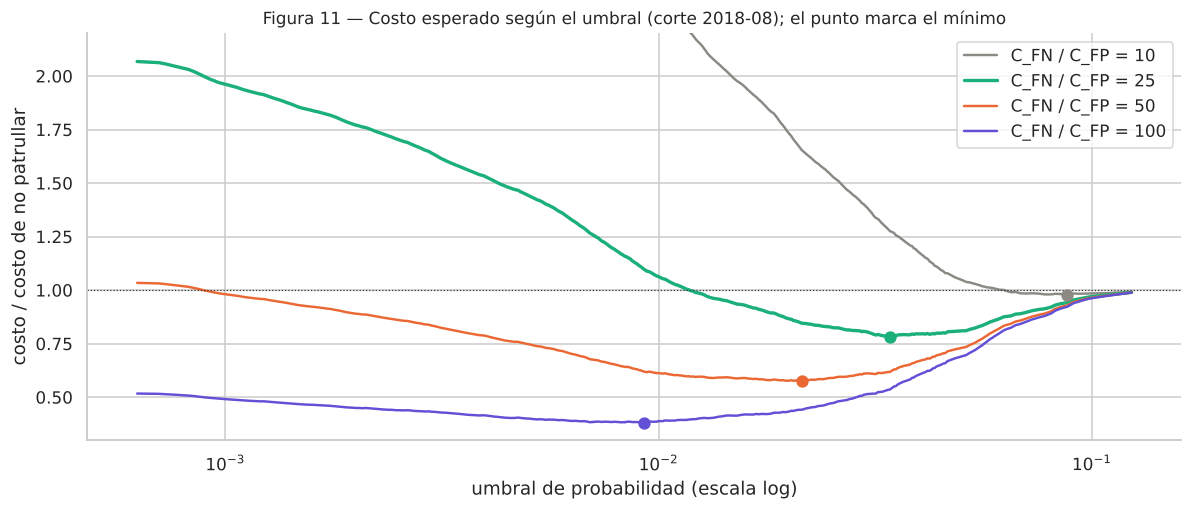

Tabla 14 — Umbral elegido en 2018-08 y aplicado sin cambios en 2019-03


,C_FN/C_FP,umbral,1/(1+k),corte,% horas-barrio alertadas,recall,precision,ahorro vs no patrullar
0,10,0.0878,0.0909,2018-08 (elige),1.4,0.083,0.117,2.1 %
1,10,0.0878,0.0909,2019-03 (aplica),1.6,0.079,0.088,-0.3 %
2,25,0.0342,0.0385,2018-08 (elige),16.6,0.546,0.062,21.7 %
3,25,0.0342,0.0385,2019-03 (aplica),17.4,0.546,0.056,17.8 %
4,50,0.0214,0.0196,2018-08 (elige),26.9,0.693,0.049,42.4 %
5,50,0.0214,0.0196,2019-03 (aplica),29.6,0.710,0.043,39.4 %
6,100,0.0093,0.0099,2018-08 (elige),46.9,0.858,0.035,61.9 %
7,100,0.0093,0.0099,2019-03 (aplica),52.8,0.878,0.030,59.3 %


In [20]:
P18, P19 = PRED["M4 · LightGBM: barrio + calendario + t (FINAL)", "2018-08-01"], PRED["M4 · LightGBM: barrio + calendario + t (FINAL)", "2019-03-01"]
Y18, Y19 = fold("2018-08-01")[1].target.values, fold("2019-03-01")[1].target.values

def costo(y, s, umbral, k):
    tn, fp, fn, tp = confusion_matrix(y, s >= umbral, labels=[0, 1]).ravel()
    return fp + k * fn, (tn, fp, fn, tp)

grid = np.quantile(P18, np.linspace(0, 0.999, 400))
fig, ax = plt.subplots(figsize=(11, 4.8))
filas, UMBRAL = [], {}
for k, col in zip([10, 25, 50, 100], [GRIS, VERDE, NARANJA, VIOLETA]):
    sin_patrulla = costo(Y18, P18, 2, k)[0]
    cs = np.array([costo(Y18, P18, u, k)[0] for u in grid]) / sin_patrulla
    UMBRAL[k] = grid[cs.argmin()]
    ax.plot(grid, cs, color=col, lw=2.2 if k == 25 else 1.6, label=f"C_FN / C_FP = {k}")
    ax.scatter(UMBRAL[k], cs.min(), color=col, s=50, zorder=3)
    for nom, y, s in [("2018-08 (elige)", Y18, P18), ("2019-03 (aplica)", Y19, P19)]:
        c_, (tn, fp, fn, tp) = costo(y, s, UMBRAL[k], k)
        filas.append({"C_FN/C_FP": k, "umbral": round(UMBRAL[k], 4), "1/(1+k)": round(1 / (1 + k), 4), "corte": nom,
                      "% horas-barrio alertadas": round(100 * (tp + fp) / len(y), 1), "recall": round(tp / (tp + fn), 3),
                      "precision": round(tp / max(tp + fp, 1), 3), "ahorro vs no patrullar": f"{100 * (1 - c_ / costo(y, s, 2, k)[0]):.1f} %"})
ax.axhline(1, color="#333", lw=.8, ls=":")
ax.set(xscale="log", xlabel="umbral de probabilidad (escala log)", ylabel="costo / costo de no patrullar", ylim=(0.3, 2.2),
       title="Figura 11 — Costo esperado según el umbral (corte 2018-08); el punto marca el mínimo")
ax.legend(); plt.tight_layout(); plt.show()
tabla(pd.DataFrame(filas), 14, "Umbral elegido en 2018-08 y aplicado sin cambios en 2019-03")

**Lectura de la Figura 11 y la Tabla 14:**

1. **El umbral óptimo coincide con la teoría.** Si las probabilidades están calibradas, el óptimo es 1/(1+k). Con k = 25
   el umbral elegido es **0.034** y la fórmula da 0.038. Es la prueba práctica de que no rebalancear dejó probabilidades
   útiles.
2. **El umbral se sostiene fuera de muestra.** Con k = 25, en 2019-03 se mantiene el recall (**0.546**) y el ahorro
   frente a no patrullar pasa de 21.7 % a **17.8 %**.
3. **Con k = 10 no conviene patrullar:** el ahorro es −0.3 % en 2019-03. Un agente tiene que evitar algo que cueste
   bastante más que su hora para que el modelo compense.

**Escenario elegido: C_FN / C_FP = 25.** El 35 % de los accidentes de `raw_accidentes` deja heridos y 29 dejan muertos,
así que un accidente evitable cuesta mucho más que una hora de patrulla. 25 es un supuesto conservador. La Figura 11
muestra cómo cambia el umbral si la Secretaría valora distinto ese costo: con k = 50 o 100 conviene alertar más
(27 % a 50 % de las horas-barrio).

## 7. Métricas más allá del ROC-AUC

Modelo final, con el umbral de 6.1 (0.0342, k = 25), en los dos cortes de validación.

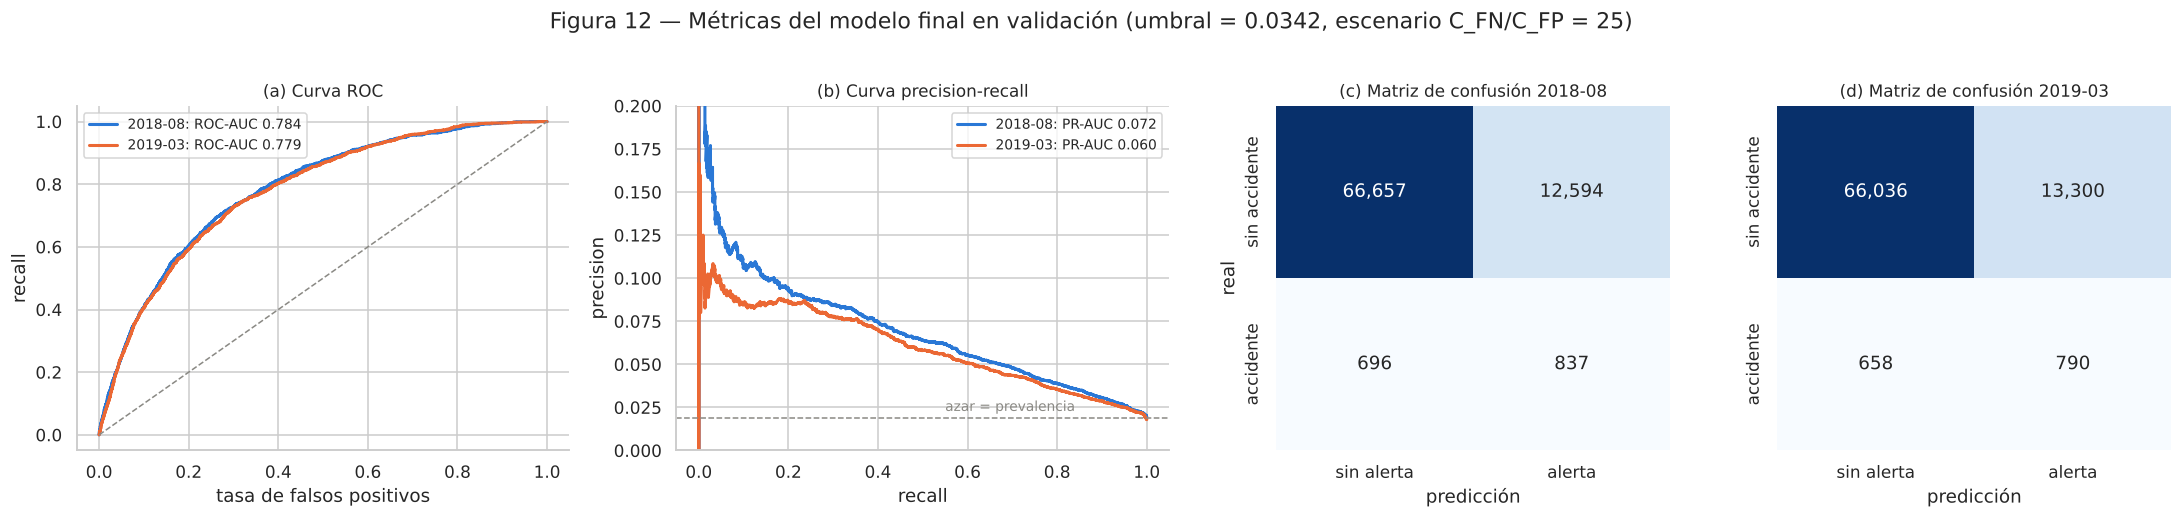

Tabla 15 — Métricas en el umbral elegido


,umbral,precision,recall,F1,especificidad,accuracy,accuracy de 'nunca hay accidente'
corte,,,,,,,
2018-08,0.034,0.062,0.546,0.112,0.841,0.835,0.981
2019-03,0.034,0.056,0.546,0.102,0.832,0.827,0.982


In [21]:
U = UMBRAL[25]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.8, 0.8]))
filas = []
for (nom, y, s), col, j in zip([("2018-08", Y18, P18), ("2019-03", Y19, P19)], [AZUL, NARANJA], [2, 3]):
    fpr, tpr, _ = roc_curve(y, s); pr, rc_, _ = precision_recall_curve(y, s)
    ax[0].plot(fpr, tpr, color=col, lw=2, label=f"{nom}: ROC-AUC {roc_auc_score(y, s):.3f}")
    ax[1].plot(rc_, pr, color=col, lw=2, label=f"{nom}: PR-AUC {average_precision_score(y, s):.3f}")
    cm = confusion_matrix(y, s >= U)
    sns.heatmap(cm, annot=np.array([[f"{v:,}" for v in r] for r in cm]), fmt="", cmap="Blues", cbar=False, ax=ax[j],
                xticklabels=["sin alerta", "alerta"], yticklabels=["sin accidente", "accidente"])
    ax[j].set(title=f"({'cd'[j - 2]}) Matriz de confusión {nom}", xlabel="predicción", ylabel="real" if j == 2 else "")
    tn, fp, fn, tp = cm.ravel()
    filas.append({"corte": nom, "umbral": round(U, 4), "precision": tp / (tp + fp), "recall": tp / (tp + fn), "F1": 2 * tp / (2 * tp + fp + fn),
                  "especificidad": tn / (tn + fp), "accuracy": (tp + tn) / cm.sum(), "accuracy de 'nunca hay accidente'": 1 - y.mean()})
ax[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1); ax[0].set(title="(a) Curva ROC", xlabel="tasa de falsos positivos", ylabel="recall")
ax[1].axhline(Y18.mean(), color=GRIS, ls="--", lw=1); ax[1].text(0.55, Y18.mean() + 0.004, "azar = prevalencia", color=GRIS, fontsize=9)
ax[1].set(title="(b) Curva precision-recall", xlabel="recall", ylabel="precision", ylim=(0, 0.2))
for a in ax[:2]: a.legend(fontsize=9)
fig.suptitle(f"Figura 12 — Métricas del modelo final en validación (umbral = {U:.4f}, escenario C_FN/C_FP = 25)", y=1.02)
plt.tight_layout(); plt.show()
tabla(pd.DataFrame(filas).set_index("corte").round(3), 15, "Métricas en el umbral elegido")

**Lectura de la Figura 12 y la Tabla 15:**

1. **Matriz de confusión (Figura 12c-d):** en 2019-03, de 1.448 accidentes el modelo anticipa **790** (recall 0.546) y
   genera 13.300 falsas alarmas. Precision **0.056**: aproximadamente 1 de cada 18 alertas tiene un accidente.
2. **Recall 0.546 con 17 % de las horas alertadas:** vigilando 1 de cada 6 horas-barrio se cubre más de la mitad de los
   accidentes.
3. **La accuracy engaña:** el modelo tiene 0.83 y la regla "nunca hay accidente" tiene **0.98**, sin servir para nada.
   Por eso el README descarta la accuracy.
4. **ROC frente a PR (Figura 12a-b):** la curva ROC se ve "buena" (0.78) porque premia ordenar bien a los 98 %
   negativos. La curva PR mide lo que le interesa a quien envía patrullas, y muestra que la precisión arranca en ~10 % y
   baja de forma gradual. El PR-AUC de 0.060–0.072 parece bajo, pero hay que compararlo con el azar, que es igual a la
   prevalencia (0.019): el modelo es **3.3 a 3.8 veces mejor que el azar**. El ROC-AUC dice que el modelo *ordena*
   bien; la PR dice que, aun ordenando bien, **la mayoría de alertas no tendrán accidente**, porque el evento es raro.
   El modelo sirve para **priorizar**, no para anticipar el accidente concreto.

## 8. Resultado oficial

El modelo final (M4, `random_state = 0`) se reentrena con **todo** el entrenamiento (hasta 2019-07-31) y predice las
80.256 parejas de la consulta del README. El archivo resultante se compara con el que se subió al leaderboard.

In [22]:
tr_f = p[(p.TW < CORTE) & (p.target >= 0)]
te_f = p[(p.TW >= CORTE) & (p.TW <= "2019-12-30 23:00")].copy()
modelo_final = lgbm(tr_f)
te_f["prob"] = modelo_final.predict_proba(te_f[VARIABLES])[:, 1]
entrega = pd.DataFrame({"id": te_f.BARRIO + "|" + te_f.TW.dt.strftime("%Y-%m-%d %H:%M:%S"), "target": te_f.prob.values})
assert len(entrega) == 80256 and entrega.id.is_unique and entrega.target.between(0, 1).all()
assert set(entrega.id) == set(consulta.BARRIO + "|" + consulta.TW)            # exactamente las filas de la consulta del README
entrega.to_csv("mi_prediccion.csv", index=False)
print(f"Entrena con {len(tr_f):,} filas (hasta {tr_f.TW.max()}), predice {len(entrega):,} filas -> mi_prediccion.csv")

SUBIDO = "mi_prediccion_Savelezc.csv"                                      # archivo que se subió al leaderboard
if os.path.exists(SUBIDO):
    s = pd.read_csv(SUBIDO).merge(entrega, on="id", suffixes=("_subido", "_notebook"))
    print(f"Comparación con {SUBIDO}: {len(s):,} ids en común, diferencia máxima = {np.abs(s.target_subido - s.target_notebook).max():.2e}")
else:
    print(f"(Para comparar con lo subido al leaderboard, copie {SUBIDO} junto al notebook.)")
tabla(entrega.target.describe().to_frame("target").T.round(4), 16, "Resumen de las 80.256 probabilidades entregadas")

Entrena con 497,376 filas (hasta 2019-07-31 23:00:00), predice 80,256 filas -> mi_prediccion.csv
Comparación con mi_prediccion_Savelezc.csv: 80,256 ids en común, diferencia máxima = 1.00e-16
Tabla 16 — Resumen de las 80.256 probabilidades entregadas


,count,mean,std,min,25%,50%,75%,max
target,80256.0,0.019,0.0222,0.0007,0.0045,0.0107,0.0254,0.1607


**Lectura:**

1. El archivo tiene exactamente las **80.256 filas** de la consulta del README, ids únicos y probabilidades entre 0 y 1.
2. Coincide con el archivo que se subió al leaderboard (`mi_prediccion_Savelezc.csv`) con una **diferencia máxima de
   1e-16**: es el mismo archivo. Este notebook reproduce exactamente el resultado oficial.
3. **Tabla 16:** la probabilidad media entregada es **1.90 %**, cerca de la prevalencia histórica (1.84 %), con un
   rango de 0.07 % a 16.1 %.

¿Qué tan bien predijo la validación el resultado del leaderboard? Además del promedio de los 6 cortes, se estima cuánto
puede variar el ROC-AUC **por puro azar** en un periodo de 5 meses: se remuestrean 1.000 veces los días del corte
2018-08, que es la misma temporada.

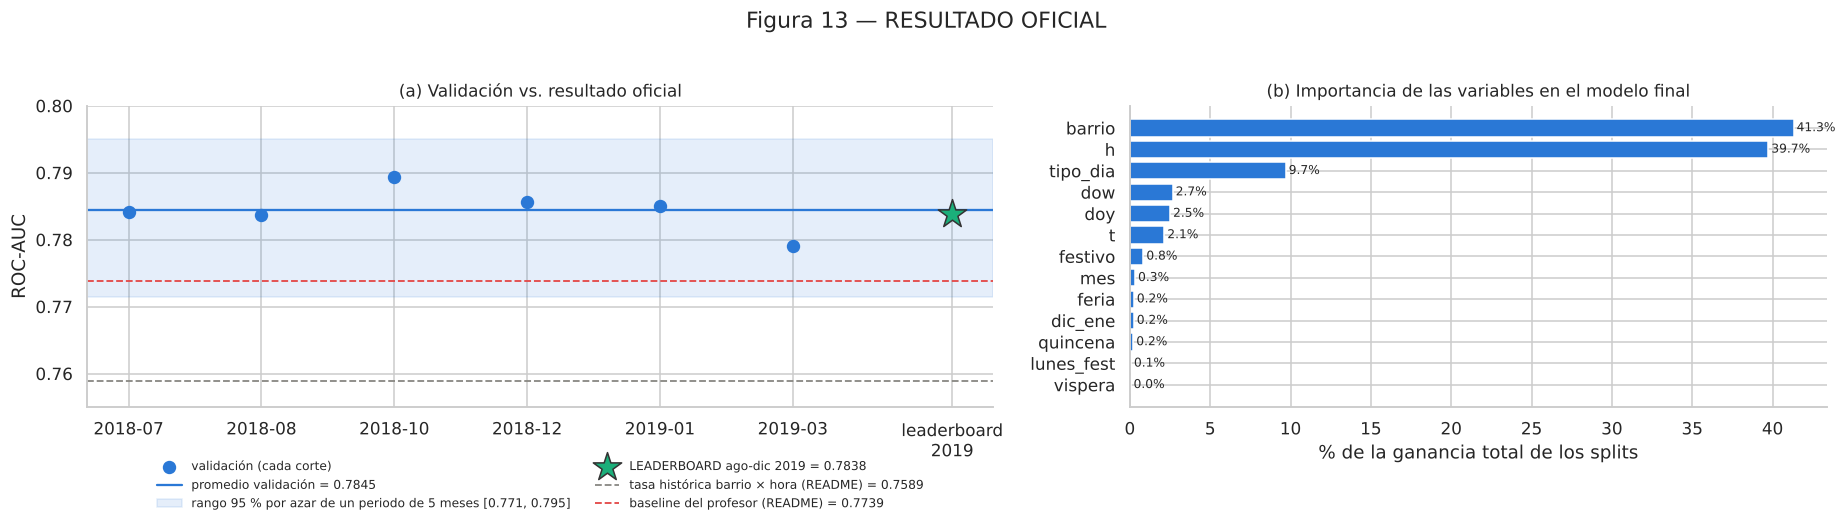

Tabla 17 — Resultado oficial frente a la validación y las referencias


,ROC-AUC
LEADERBOARD (ago-dic 2019),0.7838
validación: promedio 6 cortes,0.7845
validación: corte 2018-08 (misma temporada),0.7836
rango 95 % por azar: límite inferior,0.7715
rango 95 % por azar: límite superior,0.7950
tasa histórica barrio × hora (README),0.7589
baseline del profesor (README),0.7739


In [23]:
LEADERBOARD_AUC = 0.7838                                                     # score oficial del leaderboard (check_status)
REF = {"tasa histórica barrio × hora (README)": 0.7589, "baseline del profesor (README)": 0.7739}
M4 = "M4 · LightGBM: barrio + calendario + t (FINAL)"
rng = np.random.default_rng(SEED)
d = fold("2018-08-01")[1].TW.dt.normalize().values
idx = pd.Series(np.arange(len(d))).groupby(d).indices
dias = np.array(list(idx))
boot = [roc_auc_score(Y18[j], P18[j]) for j in
        (np.concatenate([idx[x] for x in rng.choice(dias, len(dias), replace=True)]) for _ in range(1000))]
lo, hi = np.percentile(boot, [2.5, 97.5])

fig, ax = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
x = np.arange(6)
ax[0].scatter(x, res.loc[M4].iloc[:6], color=AZUL, s=60, zorder=3, label="validación (cada corte)")
ax[0].axhline(res.loc[M4, "promedio"], color=AZUL, lw=1.5, label=f"promedio validación = {res.loc[M4, 'promedio']:.4f}")
ax[0].axhspan(lo, hi, color=AZUL, alpha=.12, label=f"rango 95 % por azar de un periodo de 5 meses [{lo:.3f}, {hi:.3f}]")
ax[0].scatter(6.2, LEADERBOARD_AUC, marker="*", s=380, color=VERDE, zorder=4, edgecolor="#333", label=f"LEADERBOARD ago-dic 2019 = {LEADERBOARD_AUC}")
for (nom, v), c in zip(REF.items(), [GRIS, ROJO]):
    ax[0].axhline(v, color=c, ls="--", lw=1.2, label=f"{nom} = {v}")
ax[0].set_xticks(list(x) + [6.2], [c[:7] for c in CORTES] + ["leaderboard\n2019"])
ax[0].set(ylabel="ROC-AUC", ylim=(0.755, 0.80), title="(a) Validación vs. resultado oficial")
ax[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
imp = pd.Series(modelo_final.booster_.feature_importance("gain"), index=VARIABLES)
imp = (100 * imp / imp.sum()).sort_values()
b = ax[1].barh(imp.index, imp.values, color=AZUL); ax[1].bar_label(b, fmt="%.1f%%", padding=2, fontsize=8)
ax[1].set(xlabel="% de la ganancia total de los splits", title="(b) Importancia de las variables en el modelo final")
fig.suptitle("Figura 13 — RESULTADO OFICIAL", y=1.02)
plt.tight_layout(); plt.show()
tabla(pd.DataFrame({"ROC-AUC": [LEADERBOARD_AUC, res.loc[M4, "promedio"], res.loc[M4, "2018-08"], lo, hi, *REF.values()]},
                   index=["LEADERBOARD (ago-dic 2019)", "validación: promedio 6 cortes", "validación: corte 2018-08 (misma temporada)",
                          "rango 95 % por azar: límite inferior", "rango 95 % por azar: límite superior", *REF]).round(4),
      17, "Resultado oficial frente a la validación y las referencias")

**Lectura de la Figura 13 y la Tabla 17 — RESULTADO OFICIAL: 0.7838.**

1. **La validación anticipó el resultado.** El leaderboard dio **0.7838**: 0.0007 por debajo del promedio de los 6
   cortes (0.7845) y prácticamente igual al corte de la misma temporada (0.7836). Cae en el centro del rango del 95 % por
   azar, [0.7715, 0.7950]. La validación walk-forward fue una estimación honesta.
2. **Frente a las referencias del README:** +0.0249 sobre la tasa histórica (0.7589) y **+0.0099 sobre el baseline del
   profesor (0.7739)**. Eso ubica la etapa 1 en el tramo de 90–100 %.
3. **Figura 13b, qué usa el modelo:** `barrio` (41 %) y `h` (40 %) explican más del 80 % de las divisiones, seguidos de
   `tipo_dia` (10 %). Es la estructura barrio × hora × tipo de día que señaló la prueba de oráculos (5.1). La tendencia
   `t`, el día del año y los festivos refinan; las banderas de temporada casi no se usan.

## 9. Caso de uso y limitaciones

### 9.1 Mapa de calor para la operación

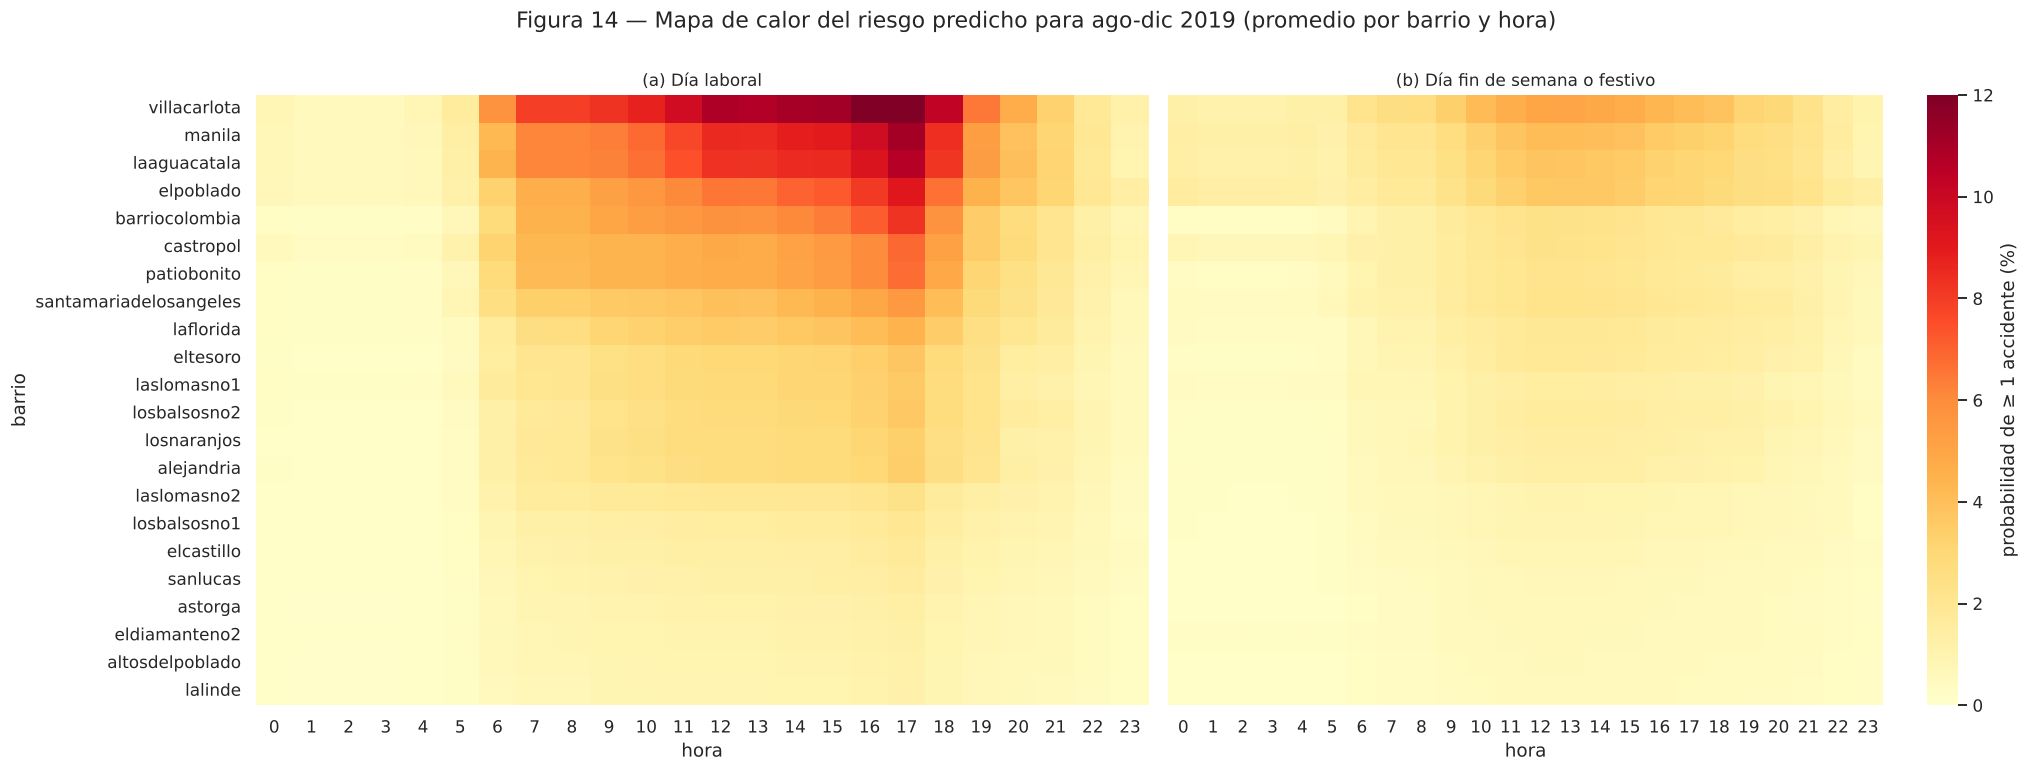

In [24]:
te_f["tipo"] = np.where((te_f.festivo == 1) | (te_f.dow >= 5), "fin de semana o festivo", "laboral")
fig, ax = plt.subplots(1, 2, figsize=(19, 7), sharey=True)
orden_b = te_f.groupby("BARRIO").prob.mean().sort_values(ascending=False).index
for j, t in enumerate(["laboral", "fin de semana o festivo"]):
    hm = te_f[te_f.tipo == t].pivot_table(index="BARRIO", columns="h", values="prob", aggfunc="mean").loc[orden_b] * 100
    sns.heatmap(hm, cmap="YlOrRd", vmin=0, vmax=12, ax=ax[j], cbar=j == 1, cbar_kws=dict(label="probabilidad de ≥ 1 accidente (%)"))
    ax[j].set(title=f"({'ab'[j]}) Día {t}", xlabel="hora", ylabel="" if j else "barrio")
fig.suptitle("Figura 14 — Mapa de calor del riesgo predicho para ago-dic 2019 (promedio por barrio y hora)", y=1.0)
plt.tight_layout(); plt.show()

**Lectura de la Figura 14:** la Secretaría puede ver de un vistazo **dónde y cuándo** concentrar agentes.

1. **Día laboral:** el riesgo se concentra entre las **7 h y las 18 h** en Villa Carlota, Manila, La Aguacatala y El
   Poblado, y el pico más alto es a las 16–17 h. En la madrugada el riesgo es mínimo en todos los barrios.
2. **Fin de semana o festivo:** el riesgo baja a la mitad o menos y se corre al mediodía (11–15 h).
3. Los barrios con menos accidentes históricos (Lalinde, Altos del Poblado, El Diamante 2) tienen riesgo bajo a
   cualquier hora.

### 9.2 Turnos: N patrullas de 4 horas

Siguiendo el caso de brigadas de las diapositivas: cada día se cubren las **4·N parejas barrio-hora de mayor
probabilidad**. Se mide en el corte de validación 2019-03, el más reciente con etiquetas.

In [25]:
va19 = fold("2019-03-01")[1].assign(prob=P19)
va19["rk"] = va19.groupby(va19.TW.dt.normalize()).prob.rank(ascending=False, method="first")
filas = []
for n in [1, 2, 3, 5, 10]:
    cub = va19.rk <= 4 * n
    filas.append({"patrullas × 4 h/día": n, "horas-barrio cubiertas por día": 4 * n, "% de las 528 diarias": round(100 * 4 * n / 528, 1),
                  "% de accidentes cubiertos": round(100 * va19.target[cub].sum() / va19.target.sum(), 1),
                  "lift frente a patrullar al azar": round(va19.target[cub].mean() / va19.target.mean(), 1)})
tabla(pd.DataFrame(filas).set_index("patrullas × 4 h/día"), 18, "Cobertura con N patrullas de 4 horas (validación mar-jul 2019)")
dia = te_f[te_f.TW.dt.normalize() == "2019-08-05"].nlargest(12, "prob")[["TW", "BARRIO", "prob"]]
dia["prob"] = (dia.prob * 100).round(2)
tabla(dia.rename(columns={"prob": "prob. (%)"}).reset_index(drop=True), 19, "Ejemplo de turno: las 12 horas-barrio de mayor riesgo el lunes 2019-08-05")

Tabla 18 — Cobertura con N patrullas de 4 horas (validación mar-jul 2019)


,horas-barrio cubiertas por día,% de las 528 diarias,% de accidentes cubiertos,lift frente a patrullar al azar
patrullas × 4 h/día,,,,
1,4,0.8,3.8,5.0
2,8,1.5,7.0,4.6
3,12,2.3,9.7,4.3
5,20,3.8,14.9,3.9
10,40,7.6,28.7,3.8


Tabla 19 — Ejemplo de turno: las 12 horas-barrio de mayor riesgo el lunes 2019-08-05


,TW,BARRIO,prob. (%)
0,2019-08-05 17:00:00,villacarlota,14.40
1,2019-08-05 16:00:00,villacarlota,12.75
2,2019-08-05 17:00:00,manila,11.78
3,2019-08-05 15:00:00,villacarlota,11.71
4,2019-08-05 17:00:00,laaguacatala,11.57
5,2019-08-05 14:00:00,villacarlota,11.57
6,2019-08-05 12:00:00,villacarlota,11.42
7,2019-08-05 13:00:00,villacarlota,11.29
8,2019-08-05 16:00:00,manila,10.54
9,2019-08-05 18:00:00,villacarlota,10.52


**Lectura de las Tablas 18 y 19:**

1. **Una patrulla de 4 horas** cubre el 0.8 % de las horas-barrio y el **3.8 %** de los accidentes: **5 veces** más que
   patrullar al azar. Con **10 patrullas** (7.6 % de las horas) se cubre el **28.7 %**.
2. El *lift* baja al agregar patrullas (de 5.0 a 3.8): las primeras toman las horas más riesgosas, y las siguientes
   horas ya son menos riesgosas.
3. **Tabla 19, ejemplo de un turno real:** para el lunes 5 de agosto de 2019, las horas prioritarias son la tarde en
   **Villa Carlota** (12–18 h, hasta 14.4 % de probabilidad), **Manila** y **La Aguacatala** (16–17 h). Un plan concreto
   sería una patrulla en Villa Carlota de 14 a 18 h y otra rotando entre Manila y La Aguacatala de 15 a 18 h.

### 9.3 Limitaciones y sesgos

1. **Solo accidentes reportados.** Los choques simples que se arreglan sin reporte no están. El modelo aprende dónde
   *se reporta*, que puede no ser exactamente dónde *ocurre*.
2. **Riesgo de retroalimentación.** Si se patrulla donde el modelo dice, allí se registrarán más incidentes, y el
   siguiente modelo reforzará esos mismos barrios. Conviene reservar parte de las patrullas para rotación aleatoria.
3. **Precisión baja por naturaleza:** ~6 % en el umbral elegido. El accidente concreto no es predecible con estos datos;
   el valor del modelo es **priorizar** y no anticipar cada evento.
4. **Información que no está en los datos:** eventos masivos, obras, cierres viales y volumen de tráfico en tiempo real.
   Serían las variables con más potencial para ir más allá de ~0.78.
5. **Calidad de la fuente:** errores de geocodificación (5 casos) y horas mal registradas (1 caso). Son pocos, pero
   muestran que la ubicación y la hora no son perfectas.
6. **Cambio en el tiempo:** algunos barrios cambian de nivel año a año. El modelo debe **reentrenarse cada mes** con los
   datos nuevos, porque 5 meses es el horizonte más largo que se validó.

## Resumen

| Punto del README | Decisión | Evidencia |
|---|---|---|
| Exploración y calidad | 20 horas sin clima, bloque sin lluvia en 2018, `HORA` en dos formatos, 1 error AM/PM, 5 accidentes mal geocodificados | Tablas 1-4, Figuras 1-3 |
| ¿Imputar clima? | **No**: el clima no separa accidentes dentro de barrio × hora y empeora el modelo | Figura 4, Tabla 5, Tabla 12 |
| Target y unión | Rejilla completa barrio × hora; target desde la tabla oficial `accidentes`; negativos = resto de la rejilla | Tablas 6-7, Figura 5 |
| Variables | Barrio categórico + calendario (festivos de Colombia, tipo de día, temporadas) + tendencia; cíclicas comparadas | Tabla 8, Figura 6 |
| Validación | Walk-forward, ventana expansiva, 6 cortes de 5 meses; la aleatoria infla +0.023 | Figura 7, Tablas 9-10 |
| Modelo | **LightGBM global**: la señal está en barrio × hora × tipo de día, no en el nivel del periodo | Figuras 8-9, Tablas 11-12 |
| Desbalance | Sin rebalanceo (ninguna técnica mejora y todas descalibran); umbral por costo (k = 25 → 0.034) | Figuras 10-11, Tablas 13-14 |
| Métricas | Recall 0.55, precision 0.06, PR-AUC 3.3-3.8 veces el azar | Figura 12, Tabla 15 |
| **Resultado oficial** | **ROC-AUC = 0.7838** (validación 0.7845), por encima del baseline del profesor (0.7739) | Figura 13, Tablas 16-17 |
| Caso de uso | Mapa de calor por barrio y hora; 1 patrulla de 4 h cubre 5 veces más accidentes que al azar | Figura 14, Tablas 18-19 |